# Toronto's 2023 and 2026 mayoral elections: what changed, where, and how it relates to neighbourhoods

**Scope.** This notebook looks only at the mayoral contests. It compares **Olivia Chow vs. Ana Bailão (2023 by-election)** with **Olivia Chow vs. Brad Bradford (2026)** and asks four questions: (1) how did the results change, (2) where did Chow gain most and least in vote share, votes and margin, (3) how do those changes relate to neighbourhood demographics, and (4) where did the vote consolidate around the two leaders.

**Two different kinds of number appear throughout, and they are not interchangeable.**

- **Official results** are the City's all-method totals (election-day, advance, mail-in, special ballots).
- **Tract results** cover only the votes the City reports for polling subdivisions that have a map polygon, spread over 2021 census tracts by population-weighted areal interpolation. I call these **mapped poll votes** (§1 shows exactly what they include and leave out). Tract-level shares, margins and counts are *estimates of the geography of mapped votes*, not observed tract ballots.

Associations with census characteristics describe **places, not people**; the census describes residents, not voters, and was taken in 2021. The 2023 contest was a stand-alone mayoral by-election and 2026 a regular municipal election, so growth in vote counts is **voting volume, not turnout**: no eligible-elector denominator is available for the tracts.

In [1]:
import json
import re
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
REPO_ROOT = Path.cwd().resolve().parents[1]
ELECTION_DIR = REPO_ROOT / "data" / "election_results"
CLEAN_DIR = ELECTION_DIR / "2026-results-clean"
MAYOR_GPKG = CLEAN_DIR / "mayor_2023_2026_ct.gpkg"
COUNCIL_GPKG = CLEAN_DIR / "councillor_2026_ct.gpkg"      # only its `wards` layer is used (boundaries/names for context)
DICTIONARY_CSV = CLEAN_DIR / "census_variable_dictionary.csv"
DTA_PATH = CLEAN_DIR / "tor_electoral_ct2021_pct.dta"

# Source files used to reconcile the tract layer with official results and to build exact ward totals
RAW_DIR = ELECTION_DIR / "2026-results-raw"
MAYOR_XLSX = RAW_DIR / "Poll_By_Poll_Mayor.xlsx"
ARCHIVE_2023 = (REPO_ROOT / "analysis" / "toronto_election_turnout" / "data" / "archive" / "elections"
                / "processed" / "municipal_2023_mayor")
CENSUS_META = REPO_ROOT / "src" / "routes" / "social-geography-and-the-mayoral-vote" / "data" / "meta.json"

PROJECTED_EPSG = 32617            # UTM 17N (metres) for maps
SPECIAL_BUCKETS = (97, 98, 99)    # 2026 poll-by-poll subdivisions with no polygon
MAPPED_2023_TYPES = ("election_day", "special")   # 2023 vote types that carry a polygon (see §1)
CANDIDATES = {2023: {"chow": "Chow Olivia", "opp": "Bailão Ana"}, 2026: {"chow": "Chow Olivia", "opp": "Bradford Brad"}}
OPP_SLUG = {2023: "bailao_ana", 2026: "bradford_brad"}

MIN_VALID_VOTES = 300             # "small tract": fewer valid votes than this in either election (about the 5th percentile)
THRESHOLDS = (0.60, 0.70, 0.80)   # concentration cut-offs, reported together
HEADLINE_THRESHOLD = 0.70
SPARSE_N = 40                     # cells with fewer tracts are flagged

# Census variables kept (raw fields only), with plain labels
PRIMARY = {
    "hhtnrent_pct": "Renter households", "ihat_med__nc": "Median household income", "vminvisi_pct": "Visible minority",
    "imstimmi_pct": "Immigrants", "edcauniv_pct": "University degree", "agec2029_pct": "Age 20-29", "agec065p_pct": "Age 65+",
    "dwtpapt__pct": "Apartment dwellings", "jwmdtran_pct": "Transit commuters", "popdsqkm__nc": "Population density",
}
# Wards named on the maps for orientation (names come from the ward layer)
LABEL_WARDS = [23, 18, 15, 2, 13, 19, 5]

CHOW, OPP, OTHER = "#1b7837", "#762a83", "#b5b5b5"     # Chow green, main-opponent purple, everyone else grey
C23, C26 = "#8c8c8c", "#1b7837"                         # 2023 grey, 2026 colour in paired charts

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.9)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. What the tract data cover

### 1.1 Source files and ward totals

I rebuild exact **ward totals** for both elections from the City's poll-by-poll results (the 2026 workbook and the archived 2023 poll data), split into votes that have a polygon ("mapped") and votes that do not. These give (a) the official all-method totals, (b) the mapped totals the tract layer should reproduce, and (c) exact ward-level figures for later summaries.

In [3]:
mayor = gpd.read_file(MAYOR_GPKG, layer="mayor_ct")
wards = gpd.read_file(COUNCIL_GPKG, layer="wards")          # boundaries and names only
dictionary = pd.read_csv(DICTIONARY_CSV)

def parse_poll_by_poll(path):
    '''Long table (ward, sub, candidate, votes) from the City's poll-by-poll workbook (one sheet per ward).'''
    rows = []
    for sheet, x in tqdm(pd.read_excel(path, sheet_name=None, header=None).items(), desc="wards", leave=False):
        ward = int(sheet.split()[1]); subs = x.iloc[1, 1:-1].astype(int).tolist()
        body = x.iloc[3:-1]; body = body[body[0].notna()]
        for name, vals in zip(body[0], body.iloc[:, 1:-1].astype(float).values):
            rows.extend((ward, s, name.strip(), v) for s, v in zip(subs, vals))
    return pd.DataFrame(rows, columns=["ward", "sub", "candidate", "votes"])

# 2026: mapped = subdivisions with a polygon; buckets 97-99 have none
src26 = parse_poll_by_poll(MAYOR_XLSX)
src26["mapped"] = ~src26["sub"].isin(SPECIAL_BUCKETS)

# 2023: candidate votes by poll, with each poll's ward and voting method
polls23 = pd.read_csv(ARCHIVE_2023 / "turnout" / "toronto_municipal_2023_mayor_turnout_subdivisions.csv",
                      usecols=["poll_id", "electoral_district_number", "vote_type"])
cand23 = pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_candidates.csv").set_index("candidate_id")["candidate_name"]
src23 = (pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_poll_candidate_votes.csv")
         .merge(polls23, on="poll_id"))
src23["candidate"] = src23["candidate_id"].map(cand23); src23["votes"] = src23["candidate_vote_count"]
src23["ward"] = src23["electoral_district_number"].astype(int); src23["mapped"] = src23["vote_type"].isin(MAPPED_2023_TYPES)
SRC = {2023: src23, 2026: src26}

def totals(src, year, mapped_only):
    '''(Chow votes, main-opponent votes, all valid candidate votes) for the whole city or by ward.'''
    d = src[src["mapped"]] if mapped_only else src
    names = CANDIDATES[year]
    by = d.groupby("ward")["votes"].sum().rename("valid").to_frame()
    by["chow"] = d[d["candidate"] == names["chow"]].groupby("ward")["votes"].sum()
    by["opp"] = d[d["candidate"] == names["opp"]].groupby("ward")["votes"].sum()
    return by

OFFICIAL = {y: totals(SRC[y], y, False) for y in SRC}      # all methods, by ward
MAPPED_SRC = {y: totals(SRC[y], y, True) for y in SRC}     # polygon-mapped votes, by ward
print("2023 voting methods in the archived data:", src23.groupby("vote_type")["votes"].sum().astype(int).to_dict())
print("Ward totals built for", len(OFFICIAL[2023]), "wards in each election")

2023 voting methods in the archived data: {'advance': 129648, 'election_day': 564267, 'mail_in': 28117, 'special': 2606}
Ward totals built for 25 wards in each election


### 1.2 Official all-method results vs. mapped poll votes

The paired bars below compare the official overall result with what the tract layer covers. "Everyone else" is all candidates other than Chow and the main opponent.

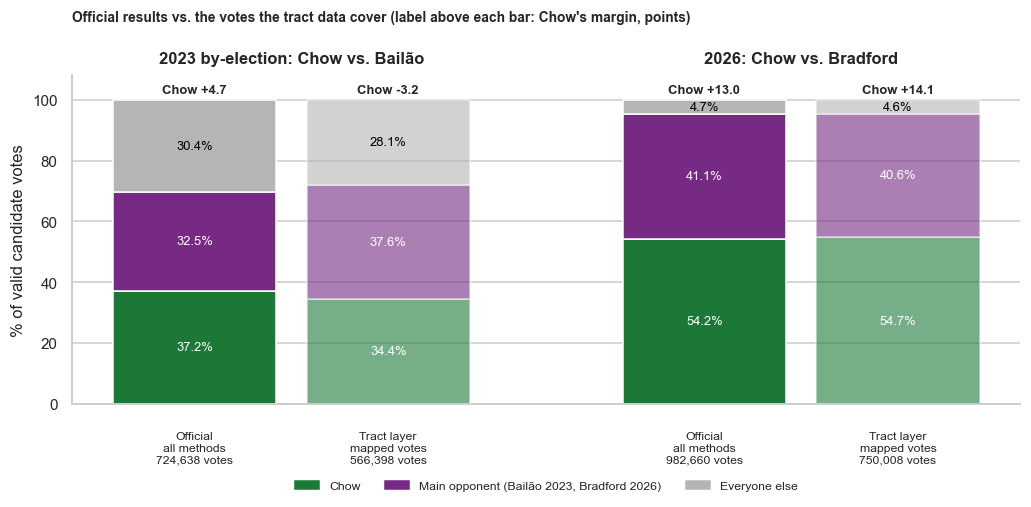

In [4]:
def city(df): return df[["chow", "opp", "valid"]].sum()
official_city = {y: city(OFFICIAL[y]) for y in OFFICIAL}
layer_city = {y: pd.Series({"chow": mayor[f"mayor{y}_chow_olivia_votes"].sum(), "opp": mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"].sum(),
                            "valid": mayor[f"mayor{y}_votes_candidates"].sum()}) for y in (2023, 2026)}

bars = [("Official\nall methods", official_city[2023], 0.0, 1.0), ("Tract layer\nmapped votes", layer_city[2023], 0.95, .6),
        ("Official\nall methods", official_city[2026], 2.5, 1.0), ("Tract layer\nmapped votes", layer_city[2026], 3.45, .6)]
fig, ax = plt.subplots(figsize=(9.5, 5))
for label, s, x, alpha in bars:
    ch, op = s["chow"] / s["valid"] * 100, s["opp"] / s["valid"] * 100; ot = 100 - ch - op
    ax.bar(x, ch, color=CHOW, alpha=alpha, width=.8); ax.bar(x, op, bottom=ch, color=OPP, alpha=alpha, width=.8)
    ax.bar(x, ot, bottom=ch + op, color=OTHER, alpha=alpha, width=.8)
    for y0, h in ((0, ch), (ch, op), (ch + op, ot)):
        ax.text(x, y0 + h / 2, f"{h:.1f}%", ha="center", va="center", fontsize=8.5, color="white" if h > 20 and y0 < ch + op else "black")
    ax.text(x, 102, f"Chow {ch - op:+.1f}", ha="center", fontsize=8.5, fontweight="bold")
    ax.text(x, -9, f"{label}\n{s['valid']:,.0f} votes", ha="center", va="top", fontsize=8)
ax.text(0.475, 112, "2023 by-election: Chow vs. Bailão", ha="center", fontweight="bold"); ax.text(2.975, 112, "2026: Chow vs. Bradford", ha="center", fontweight="bold")
ax.set(ylim=(0, 108), xlim=(-.6, 4.05), xticks=[], ylabel="% of valid candidate votes"); ax.grid(False, axis="x")
ax.legend(handles=[Patch(color=CHOW, label="Chow"), Patch(color=OPP, label="Main opponent (Bailão 2023, Bradford 2026)"), Patch(color=OTHER, label="Everyone else")],
          loc="upper center", bbox_to_anchor=(.5, -.2), ncol=3, frameon=False, fontsize=8)
ax.set_title("Official results vs. the votes the tract data cover (label above each bar: Chow's margin, points)", fontsize=9, loc="left", y=1.1, pad=14)
plt.tight_layout(); plt.show()

In [5]:
dta = pd.read_stata(DTA_PATH)
rows = []
for y in (2023, 2026):
    o, ms, lay = official_city[y], city(MAPPED_SRC[y]), layer_city[y]
    rows.append({"election": y, "official valid votes (all methods)": o["valid"], "mapped in source files": ms["valid"],
                 "upstream .dta city total": dta[f"citytotal{y}"].iloc[0], "tract layer": lay["valid"],
                 "layer as % of official": lay["valid"] / o["valid"] * 100, "official votes with no polygon": o["valid"] - ms["valid"],
                 "no-polygon share of official %": (o["valid"] - ms["valid"]) / o["valid"] * 100,
                 "mapped votes not reaching a tract": ms["valid"] - lay["valid"]})
cov = pd.DataFrame(rows).set_index("election").T
display(cov.round(1))
m23 = SRC[2023].groupby("vote_type")["votes"].sum()
print("2023 votes without a polygon = advance + mail-in:", f"{m23['advance']:,.0f} + {m23['mail_in']:,.0f} = {m23['advance'] + m23['mail_in']:,.0f}"
      f"; mapped = election day + special: {m23['election_day']:,.0f} + {m23['special']:,.0f} = {m23['election_day'] + m23['special']:,.0f}")
print("Tract layer vs. source mapped votes, Chow / main opponent (2023):",
      f"{layer_city[2023]['chow'] - city(MAPPED_SRC[2023])['chow']:+.0f} / {layer_city[2023]['opp'] - city(MAPPED_SRC[2023])['opp']:+.0f} votes;",
      "(2026):", f"{layer_city[2026]['chow'] - city(MAPPED_SRC[2026])['chow']:+.0f} / {layer_city[2026]['opp'] - city(MAPPED_SRC[2026])['opp']:+.0f} votes")

election,2023,2026
official valid votes (all methods),"724,638.00","982,660.00"
mapped in source files,"566,873.00","750,302.00"
upstream .dta city total,"566,873.00","750,302.00"
tract layer,"566,398.00","750,008.00"
layer as % of official,78.20,76.30
official votes with no polygon,"157,765.00","232,358.00"
no-polygon share of official %,21.80,23.60
mapped votes not reaching a tract,475.00,294.00


2023 votes without a polygon = advance + mail-in: 129,648 + 28,117 = 157,765; mapped = election day + special: 564,267 + 2,606 = 566,873
Tract layer vs. source mapped votes, Chow / main opponent (2023): -2 / -11 votes; (2026): -2 / +3 votes


### 1.3 Essential validation

Keys, missing census values, vote sums, denominators and small-tract counts.

In [6]:
need = list(PRIMARY)
print("Tracts:", len(mayor), "| unique IDs:", mayor["ctuid2021"].is_unique, "| CRS:", mayor.crs.to_epsg(), "| geometries valid:", bool(mayor.is_valid.all()))
miss = mayor[need].isna().sum(); print("Missing census values (primary variables):", miss[miss > 0].to_dict(),
      "| tracts:", mayor.loc[mayor[need].isna().any(axis=1), "ctuid2021"].tolist())
for y in (2023, 2026):
    votes = [c for c in mayor.columns if re.fullmatch(rf"mayor{y}_.+_votes", c) and "candidates" not in c and "cast" not in c]
    pcts = [c for c in mayor.columns if re.fullmatch(rf"mayor{y}_.+_pct", c)]
    v, cast = mayor[f"mayor{y}_votes_candidates"], mayor[f"mayor{y}_votes_cast"]
    print(f"{y}: candidate columns sum to votes_candidates: {np.allclose(mayor[votes].sum(axis=1), v)} | "
          f"shares (0-1 fractions, max {mayor[pcts].max().max():.2f}) = votes / valid candidate votes: {np.allclose(mayor[pcts[0]], mayor[votes[0]] / v)} | "
          f"tracts with <= 0 valid votes: {int((v <= 0).sum())}")
    print(f"      ballots cast {cast.sum():,.0f} vs valid candidate votes {v.sum():,.0f} (diff {cast.sum() - v.sum():+,.0f}); "
          f"cast < valid in {int((cast < v - 0.5).sum())} of 585 tracts, so tract-level 'ballots cast' is allocation noise and is not used as a turnout measure")
small = (mayor["mayor2023_votes_candidates"] < MIN_VALID_VOTES) | (mayor["mayor2026_votes_candidates"] < MIN_VALID_VOTES)
print(f"Small tracts (< {MIN_VALID_VOTES} valid votes in either election): {int(small.sum())}; they hold "
      f"{mayor.loc[small, 'mayor2026_votes_candidates'].sum() / mayor['mayor2026_votes_candidates'].sum():.1%} of mapped 2026 votes")

Tracts: 585 | unique IDs: True | CRS: 4326 | geometries valid: True
Missing census values (primary variables): {'hhtnrent_pct': 2, 'ihat_med__nc': 2, 'vminvisi_pct': 2, 'imstimmi_pct': 2, 'edcauniv_pct': 2, 'jwmdtran_pct': 2} | tracts: ['5350006.00', '5350205.00']
2023: candidate columns sum to votes_candidates: True | shares (0-1 fractions, max 0.80) = votes / valid candidate votes: True | tracts with <= 0 valid votes: 0
      ballots cast 566,890 vs valid candidate votes 566,398 (diff +492); cast < valid in 203 of 585 tracts, so tract-level 'ballots cast' is allocation noise and is not used as a turnout measure
2026: candidate columns sum to votes_candidates: True | shares (0-1 fractions, max 0.90) = votes / valid candidate votes: True | tracts with <= 0 valid votes: 0
      ballots cast 750,296 vs valid candidate votes 750,008 (diff +288); cast < valid in 204 of 585 tracts, so tract-level 'ballots cast' is allocation noise and is not used as a turnout measure
Small tracts (< 300 val

**What this shows (rechecked from the source files).**

- **2023:** the tract layer covers **78.2%** of the 724,638 official valid votes. The 157,765 votes with no polygon are exactly the advance (129,648) and mail-in (28,117) ballots; the mapped votes are election-day polls plus 2,606 special-ballot votes that the City assigns to polygons (564,267 + 2,606 = 566,873, the upstream `.dta` total). The tract layer then holds 475 fewer votes (some mapped polls do not reach any tract), and its Chow and Bailão totals are within a few votes of the source files.
- **2026:** the layer covers **76.3%** of the 982,660 official valid votes; the 232,358 votes in subdivisions 97-99 have no polygon. The City's poll-by-poll file does not say what these buckets contain, so I describe them only as "no polygon". The layer holds 294 fewer votes than the mapped source files.
- **The coverage gap matters in 2023, not much in 2026.** Officially Chow led Bailão by 4.7 points (37.2% to 32.5%); in the mapped votes she trailed by 3.2 (34.4% to 37.6%). In 2026 the official margin (+13.0) and mapped margin (+14.1) are close. So the 2023→2026 *change* in Chow's margin is **+8.3 points officially and +17.3 in the mapped votes**: the two are different quantities. The tract analysis below describes the mapped votes only, and I do not know how the omitted ballots were distributed across tracts.
- Keys, vote sums and share definitions check out (shares are fractions of valid candidate votes). `votes_cast` is not used because it disagrees with the candidate totals tract by tract.

## 2. The measures

For every tract and election, using the **same leading pair** (Chow + Bailão in 2023, Chow + Bradford in 2026):

| Measure | Definition | Unit |
|---|---|---|
| Chow share / opponent share | votes ÷ all valid candidate votes | % |
| Leading-pair share | (Chow + opponent) ÷ all valid votes | % |
| All other candidates | 100 − leading-pair share | % |
| Margin | Chow share − opponent share | percentage points |
| Vote lead | Chow votes − opponent votes | votes |
| Pair share | Chow ÷ (Chow + opponent) | % |

**Changes (2026 minus 2023)** are kept distinct: share gains in **percentage points**, additional votes in **votes**, growth as **% of the 2023 count**, and the change in the **margin** in points. Aggregates are always **pooled** (sums of votes, then ratios), never averages of tract percentages. A candidate's vote count can rise while their share or lead falls: because the number of votes cast grew, counts and shares answer different questions.

In [7]:
t = mayor[["ctuid2021", "ward_dominant", "ward_dominant_share", "area_km2"]].copy()
for y in (2023, 2026):
    s = str(y)[2:]
    v, c, o = mayor[f"mayor{y}_votes_candidates"], mayor[f"mayor{y}_chow_olivia_votes"], mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"]
    t[f"valid{s}"], t[f"chow_v{s}"], t[f"opp_v{s}"], t[f"oth_v{s}"] = v, c, o, v - c - o
    t[f"chow{s}"], t[f"opp{s}"] = c / v * 100, o / v * 100
    t[f"lp{s}"] = (c + o) / v * 100                    # leading-pair share
    t[f"oth{s}"] = 100 - t[f"lp{s}"]
    t[f"margin{s}"] = t[f"chow{s}"] - t[f"opp{s}"]
    t[f"lead_v{s}"] = c - o
    t[f"pair{s}"] = c / (c + o) * 100
t["d_chow"], t["d_opp"], t["d_lp"], t["d_oth"] = t.chow26 - t.chow23, t.opp26 - t.opp23, t.lp26 - t.lp23, t.oth26 - t.oth23
t["d_margin"], t["d_pair"] = t.margin26 - t.margin23, t.pair26 - t.pair23
t["d_chow_v"], t["d_opp_v"], t["d_valid"], t["d_lead_v"] = t.chow_v26 - t.chow_v23, t.opp_v26 - t.opp_v23, t.valid26 - t.valid23, t.lead_v26 - t.lead_v23
t["g_chow"], t["g_opp"], t["g_valid"] = t.d_chow_v / t.chow_v23 * 100, t.d_opp_v / t.opp_v23 * 100, t.d_valid / t.valid23 * 100   # % growth
# accounting benchmark: Chow's 2026 votes if her 2023 tract share had stayed constant while total valid votes changed
t["bench_v26"] = t.chow23 / 100 * t.valid26
t["volume_term"] = (t.valid26 - t.valid23) * t.chow23 / 100          # votes added by more votes cast at the 2023 share
t["share_term"] = t.valid26 * t.d_chow / 100                           # votes added by the higher share (= chow_v26 - bench_v26)
t["big"] = (t.valid23 >= MIN_VALID_VOTES) & (t.valid26 >= MIN_VALID_VOTES)
t = t.merge(mayor.drop(columns=["geometry", "ward_dominant", "ward_dominant_share", "area_km2"] + [c for c in mayor.columns if c.startswith("mayor")]), on="ctuid2021")
t = gpd.GeoDataFrame(t, geometry=mayor.geometry.values, crs=mayor.crs)
assert len(t) == 585 and np.allclose(t.volume_term + t.share_term, t.d_chow_v) and np.allclose(t.share_term, t.chow_v26 - t.bench_v26)

def pooled(df):
    '''Aggregate (pooled) shares, counts and changes for any set of tracts.'''
    o = {}
    for s in ("23", "26"):
        V, C, O = df[f"valid{s}"].sum(), df[f"chow_v{s}"].sum(), df[f"opp_v{s}"].sum()
        o.update({f"valid{s}": V, f"chow_v{s}": C, f"opp_v{s}": O, f"chow{s}": C / V * 100, f"opp{s}": O / V * 100, f"lp{s}": (C + O) / V * 100,
                  f"oth{s}": 100 - (C + O) / V * 100, f"margin{s}": (C - O) / V * 100, f"pair{s}": C / (C + O) * 100, f"lead_v{s}": C - O})
    for k in ("chow", "opp", "lp", "oth", "margin", "pair"):
        o[f"d_{k}"] = o[f"{k}26"] - o[f"{k}23"]
    o["g_valid"] = (o["valid26"] / o["valid23"] - 1) * 100; o["g_chow"] = (o["chow_v26"] / o["chow_v23"] - 1) * 100; o["g_opp"] = (o["opp_v26"] / o["opp_v23"] - 1) * 100
    o["d_chow_v"], o["d_opp_v"], o["d_valid"] = o["chow_v26"] - o["chow_v23"], o["opp_v26"] - o["opp_v23"], o["valid26"] - o["valid23"]
    o["n"] = len(df)
    return pd.Series(o)

P = pooled(t)
summary = pd.DataFrame({
    "2023": [P.valid23, P.chow_v23, P.opp_v23, P.chow23, P.opp23, P.lp23, P.oth23, P.margin23, P.lead_v23, P.pair23],
    "2026": [P.valid26, P.chow_v26, P.opp_v26, P.chow26, P.opp26, P.lp26, P.oth26, P.margin26, P.lead_v26, P.pair26]},
    index=["valid votes", "Chow votes", "Main opponent votes", "Chow share %", "Opponent share %", "Leading-pair share %", "All others %",
           "Margin (pp)", "Vote lead (votes)", "Chow share of pair %"])
summary["change"] = summary["2026"] - summary["2023"]
summary["growth %"] = [summary.loc[i, "change"] / summary.loc[i, "2023"] * 100 if i in ("valid votes", "Chow votes", "Main opponent votes") else np.nan for i in summary.index]   # not defined for the lead: its 2023 value is negative
print("Pooled mapped votes, 585 tracts (opponent = Bailão in 2023, Bradford in 2026)")
display(summary.round(1))

Pooled mapped votes, 585 tracts (opponent = Bailão in 2023, Bradford in 2026)


,2023,2026,change,growth %
valid votes,"566,398.00","750,008.00","183,610.00",32.40
Chow votes,"194,656.00","410,361.00","215,705.00",110.80
Main opponent votes,"212,730.00","304,835.00","92,105.00",43.30
Chow share %,34.40,54.70,20.30,NaN
Opponent share %,37.60,40.60,3.10,NaN
Leading-pair share %,71.90,95.40,23.40,NaN
All others %,28.10,4.60,-23.40,NaN
Margin (pp),-3.20,14.10,17.30,NaN
Vote lead (votes),"-18,074.00","105,526.00","123,600.00",NaN
Chow share of pair %,47.80,57.40,9.60,NaN


**Reading the pooled mapped totals.** Chow's mapped votes more than doubled (+215,705, +111%) while her main opponent's grew by 43% (+92,105) and total valid mapped votes by 32%. That moved her from 18,074 votes behind Bailão to 105,526 ahead of Bradford. Her share rose 20.3 points and her margin 17.3, while the leading pair's combined share rose from 71.9% to 95.4% as the rest of the field shrank from 28.1% to 4.6%. Her share of the two-candidate vote moved by a smaller 9.6 points. The official all-method figures give smaller changes (§1.3): margin +8.3, share of the pair +3.5.

## 3. Where did Chow gain? The geography of change

### 3.1 Maps

Maps use projected geometry with ward boundaries (thin grey lines) and a few ward names for orientation. **Level maps** use sequential scales (the 2023 and 2026 share maps share one scale so they can be compared directly). **Change maps** use zero-centred diverging scales when a measure has both gains and losses; where a measure rose in every tract the scale is sequential and the text says so. Different outcomes use different scales on purpose.

In [8]:
tp = t.to_crs(PROJECTED_EPSG); wp = wards.to_crs(PROJECTED_EPSG)
ward_names = wards.set_index("ward")["ward_name"]
label_pts = wp[wp["ward"].isin(LABEL_WARDS)].copy(); label_pts["pt"] = label_pts.geometry.representative_point()

def change_scale(series, pct=98, diverging_cmap="PRGn", seq_cmap="Greens"):
    '''Zero-centred diverging scale if the measure has gains and losses, else a sequential scale. Returns (cmap, norm, note).'''
    lim = np.nanpercentile(np.abs(series), pct)
    if series.min() < 0:
        return diverging_cmap, TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), f"{int((series < 0).sum())} of {series.notna().sum()} tracts decreased"
    return seq_cmap, Normalize(vmin=0, vmax=lim), f"every one of {series.notna().sum()} tracts increased"

def draw_map(fig, ax, col, cmap, norm, title, unit, labels=True, extend="neither"):
    tp.plot(column=col, cmap=cmap, norm=norm, ax=ax, linewidth=0, missing_kwds={"color": "#e0e0e0", "hatch": "///", "edgecolor": "#aaaaaa"})
    wp.boundary.plot(ax=ax, color="#444444", linewidth=.3, alpha=.55)
    if labels:
        for _, r in label_pts.iterrows():
            ax.annotate(r["ward_name"].replace("-", "–"), (r["pt"].x, r["pt"].y), fontsize=5.8, ha="center", color="#222", alpha=.85,
                        bbox=dict(boxstyle="round,pad=.12", fc="white", ec="none", alpha=.55))
    ax.set_axis_off(); ax.set_title(title, fontsize=9)
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal", fraction=.04, pad=.01, shrink=.8, label=unit, extend=extend)

def map_row(specs, figsize=(17, 6)):
    fig, axes = plt.subplots(1, len(specs), figsize=figsize)
    for ax, spec in zip(np.atleast_1d(axes), specs):
        draw_map(fig, ax, **spec)
    plt.tight_layout(); plt.show()

**Group A: Chow's support and share gain.** The first two maps show Chow's share of all valid mapped votes in each election on one shared scale; the third shows the change.

Change in Chow's share: every one of 585 tracts increased | range 3.9 to 32.6 pp, median 20.0
Highest 2026 Chow share: tract 5350002.00, 90.4% on 332 valid votes (605 census residents)


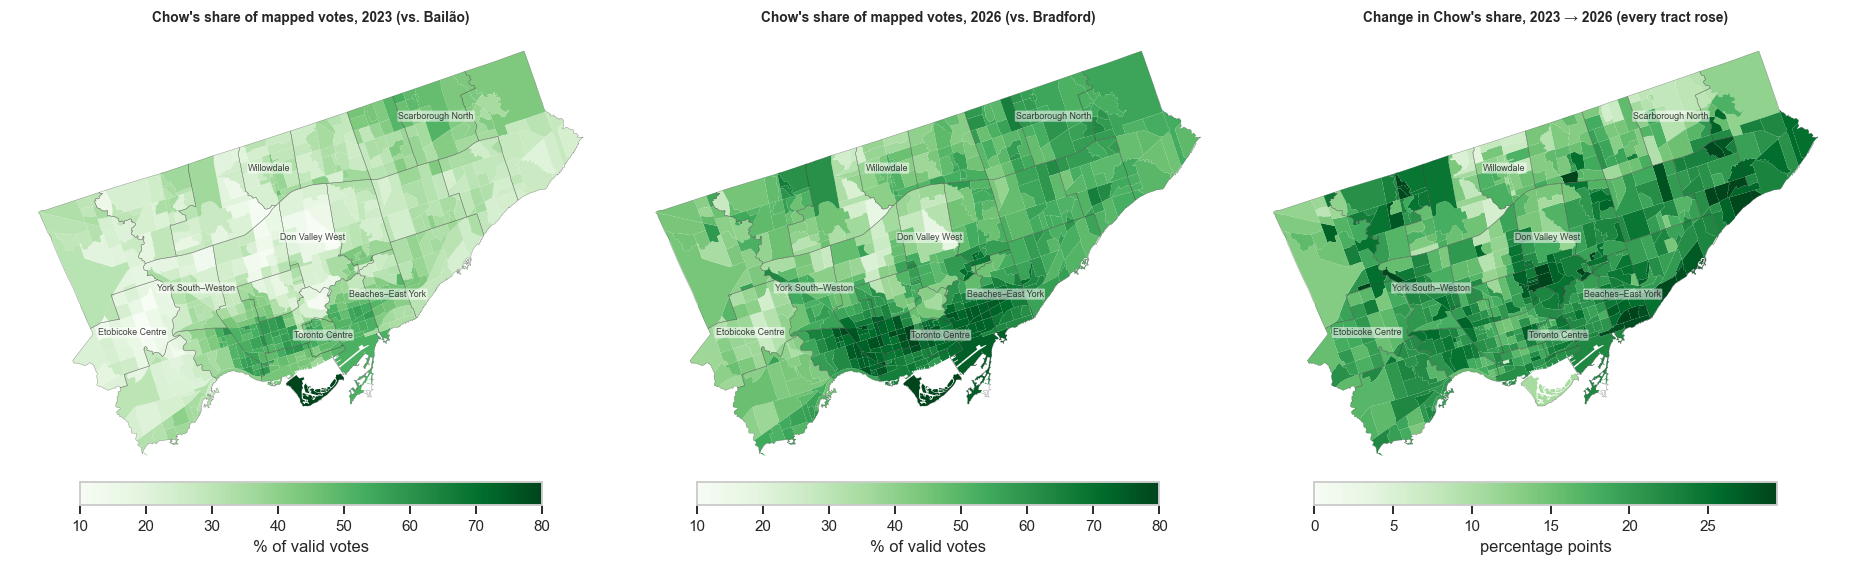

In [9]:
cm_share = Normalize(vmin=10, vmax=80)
cmap_d, norm_d, note_d = change_scale(t.d_chow)
print("Change in Chow's share:", note_d, f"| range {t.d_chow.min():.1f} to {t.d_chow.max():.1f} pp, median {t.d_chow.median():.1f}")
top = t.loc[t.chow26.idxmax()]; print(f"Highest 2026 Chow share: tract {top.ctuid2021}, {top.chow26:.1f}% on {top.valid26:.0f} valid votes ({top.pop21 if 'pop21' in top else top.den_agec_tot:.0f} census residents)")
map_row([dict(col="chow23", cmap="Greens", norm=cm_share, title="Chow's share of mapped votes, 2023 (vs. Bailão)", unit="% of valid votes"),
         dict(col="chow26", cmap="Greens", norm=cm_share, title="Chow's share of mapped votes, 2026 (vs. Bradford)", unit="% of valid votes"),
         dict(col="d_chow", cmap=cmap_d, norm=norm_d, title="Change in Chow's share, 2023 → 2026 (every tract rose)", unit="percentage points")])

**What the maps show.** Chow's 2023 support (left) was concentrated in a belt of central, east-end and west-end downtown tracts; by 2026 (middle) that belt had deepened and widened outward to most of the east side and parts of Etobicoke, and the weakest areas shrank to a band across the north-west and central-north of the city. Her share rose in every one of the 585 tracts (right), by 3.9 to 32.6 points (median 20.0). The smallest gains are visible in a block of pale tracts around the labelled Willowdale and Scarborough North wards and in the north-west; the largest in the central east-end and downtown tracts. (The very dark tract in the harbour area is the highest-share tract in 2026, 90.4% on only 332 valid votes, so its colour reflects a small number of votes.)

**Group B: gains against the main opponent.** The first map is the change in Chow's margin (her share minus her opponent's). The second is her share of the two-candidate vote, a different view that ignores everyone else. The third classifies each tract by who led the *head-to-head* contest in each year; this is a pairwise lead, not an outright win (§3.5).

Change in margin: 41 of 585 tracts decreased | change in pair share: 43 of 585 tracts decreased


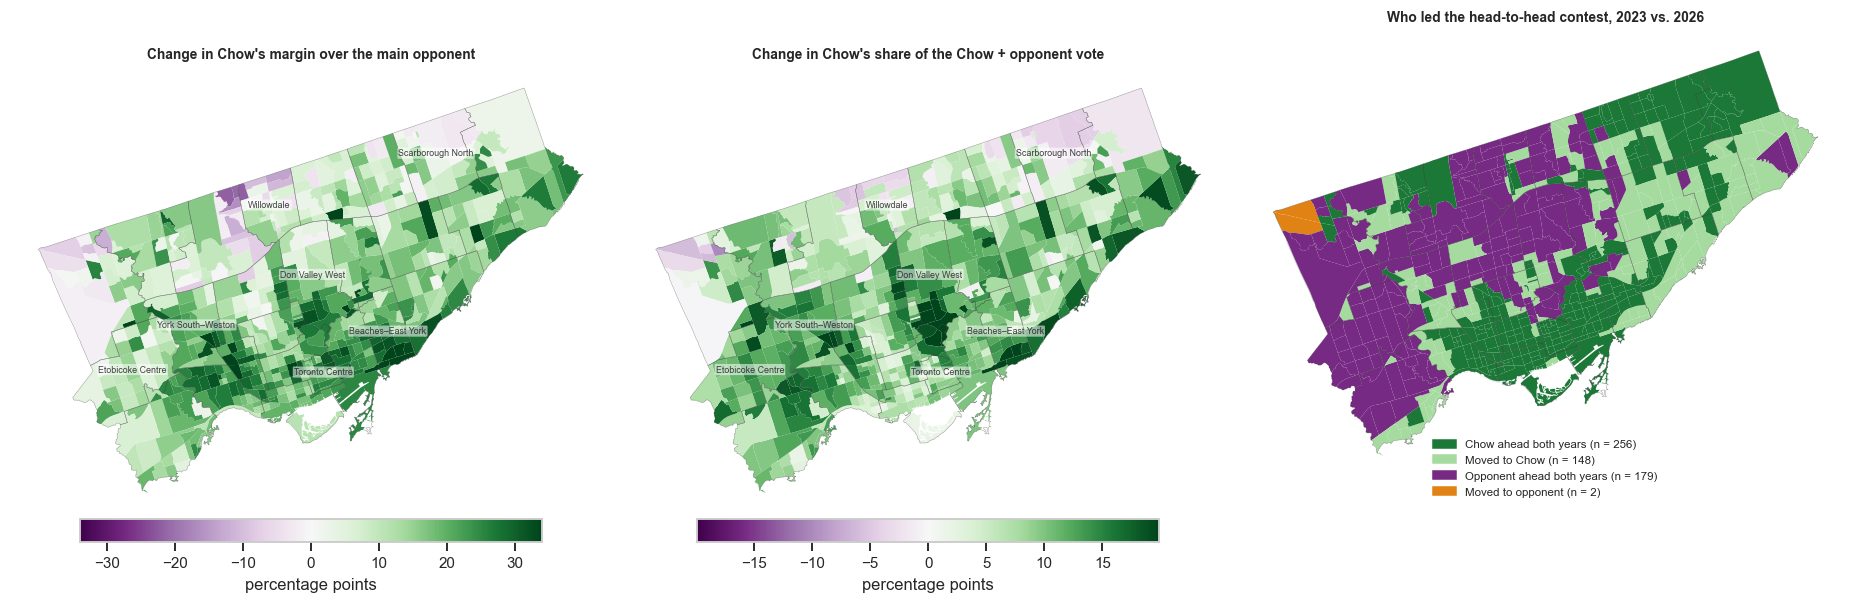

In [10]:
t["lead_status"] = np.select([(t.pair23 > 50) & (t.pair26 > 50), (t.pair23 <= 50) & (t.pair26 > 50), (t.pair23 > 50) & (t.pair26 <= 50)],
                             ["Chow ahead both years", "Moved to Chow", "Moved to opponent"], "Opponent ahead both years")
tp = t.to_crs(PROJECTED_EPSG)
status_colours = {"Chow ahead both years": "#1b7837", "Moved to Chow": "#a6dba0", "Opponent ahead both years": "#762a83", "Moved to opponent": "#e08214"}
cat = pd.Categorical(tp["lead_status"], categories=list(status_colours)); tp["lead_code"] = cat.codes
cmap_m, norm_m, note_m = change_scale(t.d_margin); cmap_p, norm_p, note_p = change_scale(t.d_pair)
print("Change in margin:", note_m, "| change in pair share:", note_p)
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
draw_map(fig, axes[0], "d_margin", cmap_m, norm_m, "Change in Chow's margin over the main opponent", "percentage points")
draw_map(fig, axes[1], "d_pair", cmap_p, norm_p, "Change in Chow's share of the Chow + opponent vote", "percentage points")
ax = axes[2]
tp.plot(column="lead_code", cmap=ListedColormap(list(status_colours.values())), ax=ax, linewidth=0, categorical=False)
wp.boundary.plot(ax=ax, color="#444", linewidth=.3, alpha=.55); ax.set_axis_off(); ax.set_title("Who led the head-to-head contest, 2023 vs. 2026", fontsize=9)
ax.legend(handles=[Patch(color=c, label=f"{k} (n = {int((t.lead_status == k).sum())})") for k, c in status_colours.items()], loc="lower center", bbox_to_anchor=(.5, -.07), fontsize=7.5, frameon=False)
plt.tight_layout(); plt.show()

**Margin and head-to-head.** The margin and pair-share maps are close cousins and show the same geography, but they differ from the share-gain map: they have losers. 41 tracts saw Chow's margin narrow and 43 saw her share of the two-candidate vote fall; they cluster along the northern edge and in the far north-west. The right-hand map shows the head-to-head result: 256 tracts where she led both years, **148 that moved to her**, 179 where the opponent led both times and only 2 that moved to the opponent. The 179 are concentrated in the north-west, north and parts of the west end; the tracts that moved to Chow form a belt between her 2023 core and those areas.

**Group C: votes.** Additional Chow votes (2026 minus 2023) and growth in all mapped valid votes. Large raw gains can reflect large tracts, more votes cast, a higher share, or all three, so these maps are read alongside the share maps (§4).

Additional Chow votes: 1 of 585 tracts decreased | median 332, range -23 to 1429
Growth in total valid mapped votes: 8 of 585 tracts decreased | median 33%, 5th-95th percentile 9% to 75% (colour scale clipped at the 97th percentile)


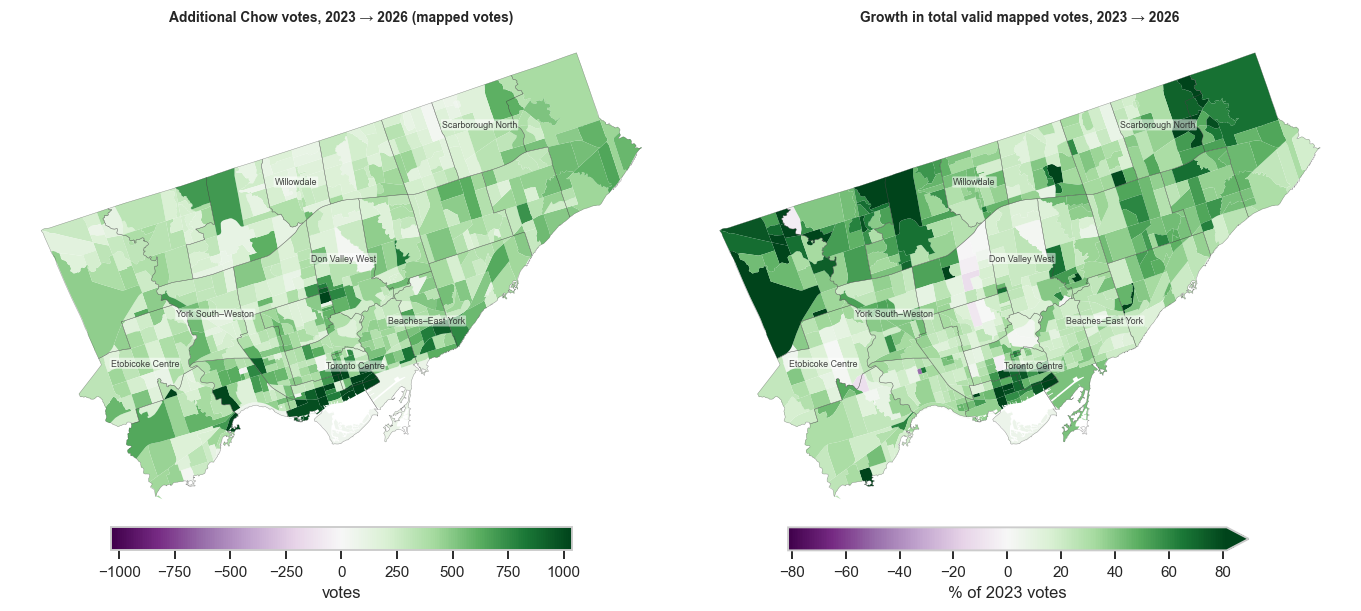

In [11]:
cmap_v, norm_v, note_v = change_scale(t.d_chow_v); cmap_g, norm_g, note_g = change_scale(t.g_valid, pct=97)
print("Additional Chow votes:", note_v, f"| median {t.d_chow_v.median():.0f}, range {t.d_chow_v.min():.0f} to {t.d_chow_v.max():.0f}")
print("Growth in total valid mapped votes:", note_g, f"| median {t.g_valid.median():.0f}%, 5th-95th percentile {t.g_valid.quantile(.05):.0f}% to {t.g_valid.quantile(.95):.0f}% (colour scale clipped at the 97th percentile)")
map_row([dict(col="d_chow_v", cmap=cmap_v, norm=norm_v, title="Additional Chow votes, 2023 → 2026 (mapped votes)", unit="votes"),
         dict(col="g_valid", cmap=cmap_g, norm=norm_g, title="Growth in total valid mapped votes, 2023 → 2026", unit="% of 2023 votes", extend="max")], figsize=(12.5, 6))

**Votes are a different map from shares.** Additional Chow votes (left) are largest in central and waterfront downtown tracts and the east end (up to about 1,400 added in one tract; median 332; one tract lost 23), and smallest in thinly populated north-west and north-central tracts. Growth in total valid votes (right) is a different pattern: the fastest growth (above 60-80%) is in a few large tracts at the north-west and north-east edges and in downtown south tracts, and the slowest in a band of central and midtown tracts (8 tracts fell). Because the polling-subdivision polygons differ between the two elections, extreme tract-level count changes can partly reflect allocation differences, so these maps are best read for broad patterns.

### 3.2 Persistence and the size of the gains

Left: each dot is a tract; the dashed line is "no change". Middle: the same for the main opponent, which is a *geographic* comparison of two different candidates, not the same voters. Right: of the 585 tracts, how many stayed in the same fifth (quintile) of Chow's share, a measure of whether the pattern of strong and weak areas persisted even though every tract rose.

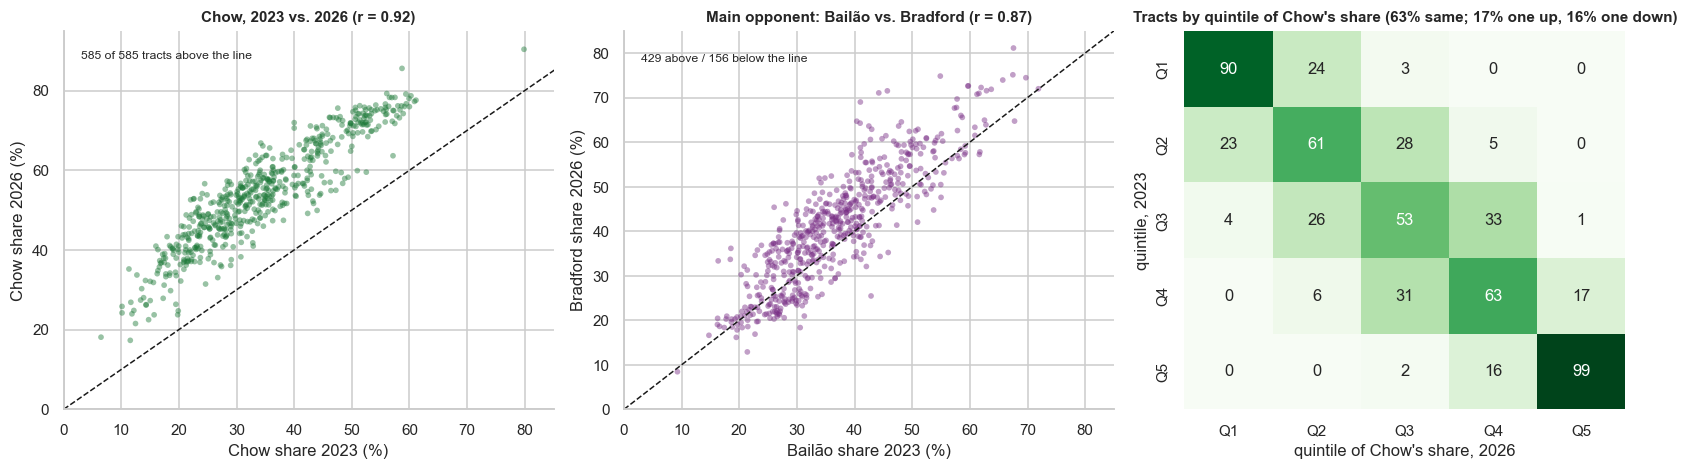

Tracts that moved two or more quintiles: 21 of 585
Spearman rank correlation of tract shares across the two elections: Chow 0.91; main opponent 0.87


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, .9]})
a = ax[0]; a.scatter(t.chow23, t.chow26, s=14, alpha=.45, color=CHOW, edgecolor="none"); a.plot([0, 90], [0, 90], "k--", lw=1)
a.set(xlim=(0, 85), ylim=(0, 95), xlabel="Chow share 2023 (%)", ylabel="Chow share 2026 (%)", title=f"Chow, 2023 vs. 2026 (r = {t[['chow23', 'chow26']].corr().iloc[0, 1]:.2f})")
a.text(3, 88, f"{int((t.chow26 > t.chow23).sum())} of 585 tracts above the line", fontsize=8)
a = ax[1]; a.scatter(t.opp23, t.opp26, s=14, alpha=.45, color=OPP, edgecolor="none"); a.plot([0, 90], [0, 90], "k--", lw=1)
a.set(xlim=(0, 85), ylim=(0, 85), xlabel="Bailão share 2023 (%)", ylabel="Bradford share 2026 (%)", title=f"Main opponent: Bailão vs. Bradford (r = {t[['opp23', 'opp26']].corr().iloc[0, 1]:.2f})")
a.text(3, 78, f"{int((t.opp26 > t.opp23).sum())} above / {int((t.opp26 < t.opp23).sum())} below the line", fontsize=8)
q23, q26 = pd.qcut(t.chow23, 5, labels=False), pd.qcut(t.chow26, 5, labels=False)
trans = pd.crosstab(q23, q26); stay = np.trace(trans.values) / trans.values.sum()
sns.heatmap(trans, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[2], xticklabels=[f"Q{i}" for i in range(1, 6)], yticklabels=[f"Q{i}" for i in range(1, 6)])
ax[2].set(xlabel="quintile of Chow's share, 2026", ylabel="quintile, 2023", title=f"Tracts by quintile of Chow's share ({stay:.0%} same; {np.trace(trans.values, 1) / trans.values.sum():.0%} one up, {np.trace(trans.values, -1) / trans.values.sum():.0%} one down)")
plt.tight_layout(); plt.show()
print(f"Tracts that moved two or more quintiles: {int(np.abs(q26 - q23).ge(2).sum())} of 585")
print(f"Spearman rank correlation of tract shares across the two elections: Chow {stats.spearmanr(t.chow23, t.chow26)[0]:.2f}; main opponent {stats.spearmanr(t.opp23, t.opp26)[0]:.2f}")

**Persistence beside broad gains.** Every dot in the left panel is above the line, yet the ordering of places barely changed: Chow's tract shares correlate at r = 0.92 across the elections, and 63% of tracts stayed in the same fifth of her share (another 33% moved one fifth; only 21 tracts, 3.6%, moved two or more). Bradford's share looks like Bailão's (r = 0.87), though the cloud is wider and 429 of 585 tracts sit above the line. This is a statement about places: strong persistence of rank is compatible with large and geographically uneven changes in level.

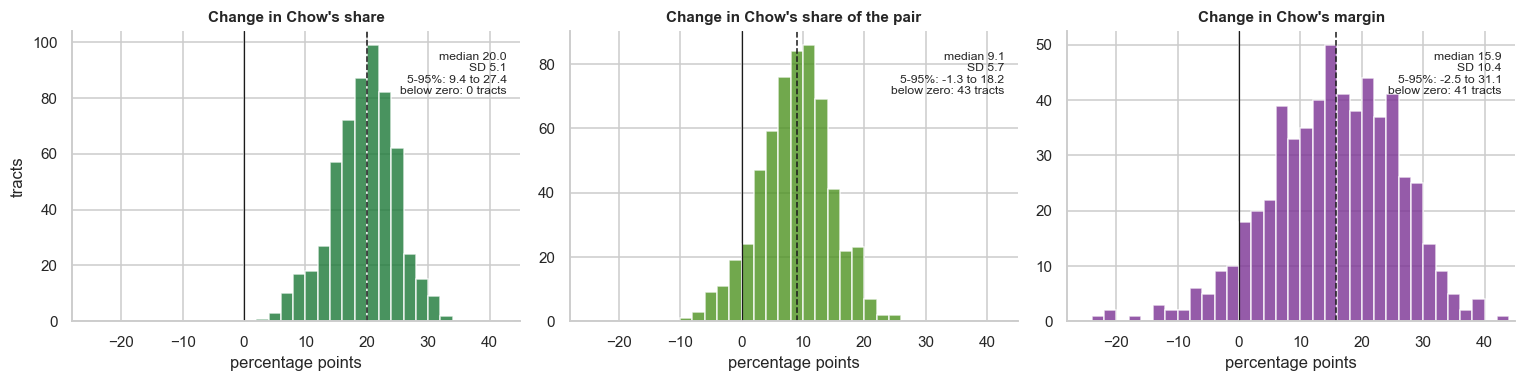

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for a, (col, ttl, colr) in zip(ax, (("d_chow", "Change in Chow's share", CHOW), ("d_pair", "Change in Chow's share of the pair", "#4d9221"), ("d_margin", "Change in Chow's margin", "#7b3294"))):
    a.hist(t[col], bins=np.arange(-30, 46, 2), color=colr, alpha=.8, edgecolor="white"); a.axvline(0, color="k", lw=.8)
    a.axvline(t[col].median(), color="k", ls="--", lw=1)
    a.set(title=ttl, xlabel="percentage points", xlim=(-28, 45))
    q = t[col].quantile([.05, .95]); a.text(.97, .93, f"median {t[col].median():.1f}\nSD {t[col].std():.1f}\n5-95%: {q.iloc[0]:.1f} to {q.iloc[1]:.1f}\nbelow zero: {int((t[col] < 0).sum())} tracts",
                                           transform=a.transAxes, ha="right", va="top", fontsize=8)
ax[0].set_ylabel("tracts"); plt.tight_layout(); plt.show()

**How uniform was the gain?** Chow's share gain is tightly bunched (median 20.0, SD 5.1, 90% of tracts between 9.4 and 27.4 points, none below zero), so it was **broad, though not uniform**: the middle and the extremes differ by ten points or more. Her margin gain is twice as variable (SD 10.4; 41 tracts below zero) and her share of the pair varies in between (SD 5.7; 43 below zero). The same places shift less when the field is ignored: the two-candidate views are where real differences between neighbourhoods appear.

### 3.3 Where gains were largest and smallest

Tracts with fewer than 300 valid votes in either election are excluded here, so that noise in small tracts does not dominate the extremes. Tracts are grouped by the ward that holds most of each (an approximation to ward geography, not official ward totals). The bars count how many of the tracts in the **top 10%** and **bottom 10%** of share gain, and of margin gain, fall in each ward.

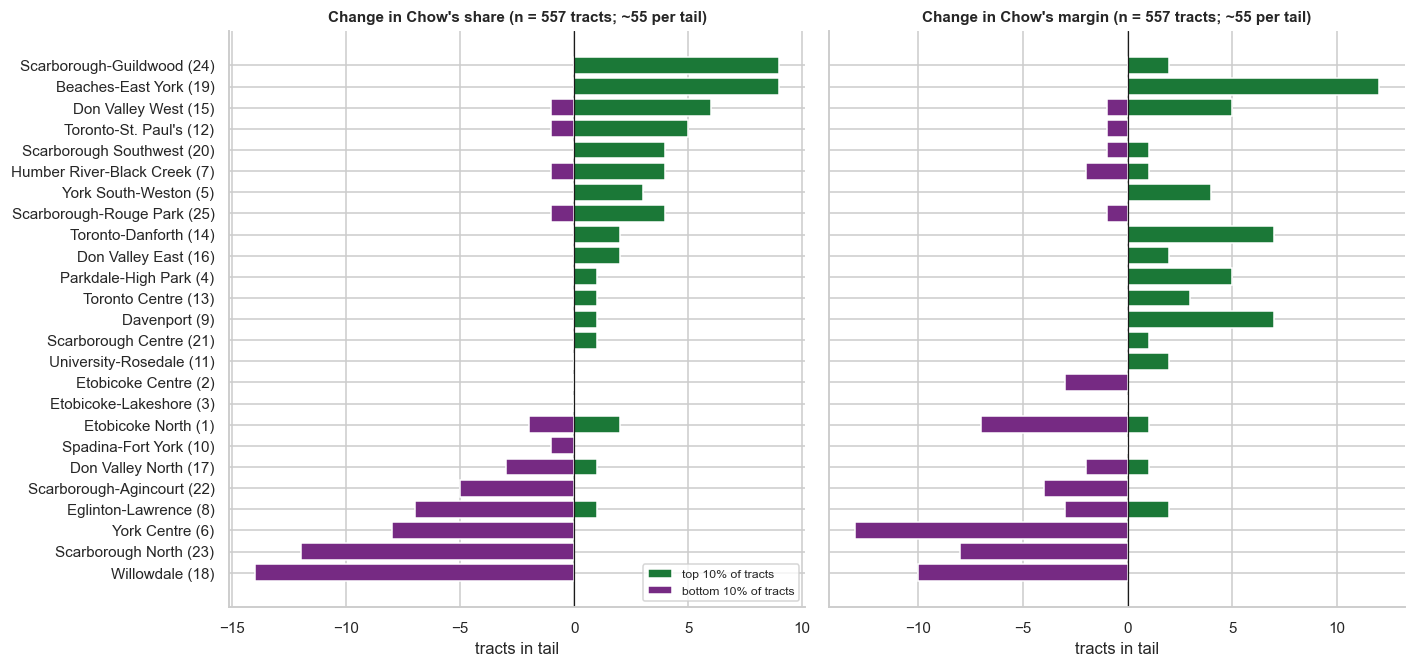

Tracts in the top-10% tails for share gain and margin gain overlap: 29 of 56


In [14]:
b = t[t.big].copy()
fig, ax = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
order = None
for a, (col, ttl) in zip(ax, (("d_chow", "Change in Chow's share"), ("d_margin", "Change in Chow's margin"))):
    top, bot = b[col] >= b[col].quantile(.9), b[col] <= b[col].quantile(.1)
    cnt = pd.DataFrame({"top": b[top].groupby("ward_dominant").size(), "bottom": b[bot].groupby("ward_dominant").size()}).reindex(range(1, 26)).fillna(0)
    if order is None:                       # order wards by the first panel (share gain) and keep it for the second
        order = (cnt["top"] - cnt["bottom"]).sort_values().index
    c2 = cnt.loc[order]; lab = [f"{ward_names[w]} ({w})" for w in c2.index]
    a.barh(lab, c2["top"], color=CHOW, label="top 10% of tracts"); a.barh(lab, -c2["bottom"], color=OPP, label="bottom 10% of tracts")
    a.axvline(0, color="k", lw=.8); a.set(title=ttl + f" (n = {len(b)} tracts; ~{int(len(b) * .1)} per tail)", xlabel="tracts in tail")
ax[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
print(f"Tracts in the top-10% tails for share gain and margin gain overlap: {int(((b.d_chow >= b.d_chow.quantile(.9)) & (b.d_margin >= b.d_margin.quantile(.9))).sum())} of {int((b.d_chow >= b.d_chow.quantile(.9)).sum())}")

**Largest and smallest gains by ward.** Of the roughly 55 tracts in each tail, the smallest share gains cluster in Willowdale (14 tracts), Scarborough North (12), York Centre (8) and Eglinton-Lawrence (7); the largest in Scarborough-Guildwood and Beaches-East York (9 each) and Don Valley West (6). For margin, the bottom tail is York Centre (13 tracts), Willowdale (10), Scarborough North (8) and Etobicoke North (7); the top tail is Beaches-East York (12), Toronto-Danforth and Davenport (7 each). The two top-10% lists overlap substantially (29 of 56 tracts are in both), so share and margin gains largely point to the same places.

### 3.4 Do share, margin and vote gains agree?

Each panel compares two ways of measuring the same tract's gain. The purple points are tracts where Chow's **share rose but her lead over the opponent narrowed** (left), or where she **gained votes but her vote lead shrank** (middle and right use additional votes). Raw vote gains scale with tract size, so point size shows the tract's 2023 valid votes.

Share rose but margin narrowed: 41 tracts. Chow added votes but her vote lead over the opponent shrank: 55 tracts. Chow's votes fell: 1 tracts.


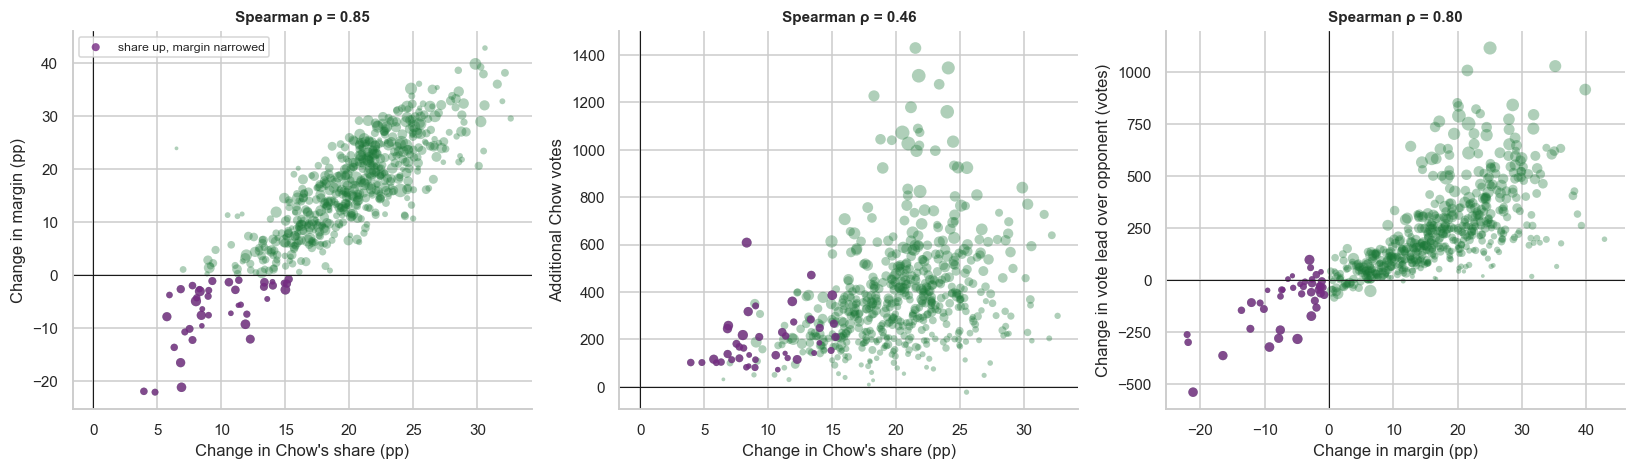

Wards (dominant-ward tract groups) holding the most tracts where share rose but margin narrowed: {'York Centre': 13, 'Etobicoke North': 8, 'Willowdale': 7, 'Scarborough North': 5, 'Scarborough-Agincourt': 3, 'Don Valley North': 2}
Correlation of tract size (2023 valid votes) with: additional Chow votes 0.77 | share gain 0.13 | margin gain 0.20 (Spearman)


In [15]:
shrink = (t.d_chow > 0) & (t.d_margin < 0); shrink_v = (t.d_chow_v > 0) & (t.d_lead_v < 0)
print(f"Share rose but margin narrowed: {int(shrink.sum())} tracts. Chow added votes but her vote lead over the opponent shrank: {int(shrink_v.sum())} tracts. "
      f"Chow's votes fell: {int((t.d_chow_v < 0).sum())} tracts.")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
size = t.valid23 / t.valid23.max() * 80 + 6
for a, (x, y, xl, yl) in zip(ax, (("d_chow", "d_margin", "Change in Chow's share (pp)", "Change in margin (pp)"),
                                  ("d_chow", "d_chow_v", "Change in Chow's share (pp)", "Additional Chow votes"),
                                  ("d_margin", "d_lead_v", "Change in margin (pp)", "Change in vote lead over opponent (votes)"))):
    a.scatter(t[x], t[y], s=size, alpha=.35, color=CHOW, edgecolor="none")
    a.scatter(t.loc[shrink, x], t.loc[shrink, y], s=size[shrink], alpha=.8, color=OPP, edgecolor="none", label="share up, margin narrowed" if x == "d_chow" else None)
    a.axhline(0, color="k", lw=.7); a.axvline(0, color="k", lw=.7)
    a.set(xlabel=xl, ylabel=yl, title=f"Spearman ρ = {stats.spearmanr(t[x], t[y])[0]:.2f}")
ax[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()
print("Wards (dominant-ward tract groups) holding the most tracts where share rose but margin narrowed:", t[shrink].ward_dominant.map(ward_names).value_counts().head(6).to_dict())
print("Correlation of tract size (2023 valid votes) with: additional Chow votes %.2f | share gain %.2f | margin gain %.2f (Spearman)" %
      (stats.spearmanr(t.valid23, t.d_chow_v)[0], stats.spearmanr(t.valid23, t.d_chow)[0], stats.spearmanr(t.valid23, t.d_margin)[0]))

**Different gain measures mostly agree, with informative exceptions.** Share gain and margin gain are strongly related (ρ = 0.85) and so are margin and vote-lead change (0.80), but additional votes are only loosely related to share gain (0.46) because they depend on tract size (ρ = 0.77 with 2023 votes). So the biggest raw gains are not the biggest shifts. In **41 tracts Chow's share rose but her margin narrowed** (the opponent's share rose even faster), and in 55 she added votes while her vote lead over the opponent shrank. They sit mostly in York Centre (13 tracts), Etobicoke North (8), Willowdale (7) and Scarborough North (5), and they are the tracts with the smallest share gains.

### 3.5 Who led: head-to-head vs. outright

A **head-to-head lead** (pair share above 50%) is not the same as winning a tract outright, because other candidates' votes matter. The layer groups all other candidates into one "other" bucket, which cannot be treated as a single candidate. A tract can therefore be assigned an outright winner among the *named* candidates only where the combined "other" bucket is smaller than the leader's share (so no hidden candidate can have led); otherwise it is marked undetermined.

In [16]:
named = {2023: ["chow_olivia", "bailao_ana", "saunders_mark", "furey_anthony", "hunter_mitzie", "brown_chloe", "bradford_brad"], 2026: ["chow_olivia", "bradford_brad"]}
def plurality(y):
    cols = [f"mayor{y}_{n}_pct" for n in named[y]]
    top, who = mayor[cols].max(axis=1), mayor[cols].idxmax(axis=1).str.replace(f"mayor{y}_", "", regex=False).str.replace("_pct", "", regex=False)
    other = mayor[f"mayor{y}_other_pct"]
    return who.where(top >= other, "undetermined")        # a single hidden candidate cannot exceed the whole bucket
w = pd.DataFrame({"2023": plurality(2023), "2026": plurality(2026)})
print("Tracts by outright plurality among named candidates:"); display(pd.DataFrame({y: w[y].value_counts() for y in w}).fillna(0).astype(int))
cross = pd.crosstab(t.lead_status, "tracts").reindex(list(status_colours)); print("Head-to-head lead (pair share > 50%):"); display(cross)
print(f"2023: Chow led head-to-head in {int((t.pair23 > 50).sum())} tracts but was the plurality leader in {int((w['2023'] == 'chow_olivia').sum())}; "
      f"2026: {int((t.pair26 > 50).sum())} vs. {int((w['2026'] == 'chow_olivia').sum())}")

Tracts by outright plurality among named candidates:


,2023,2026
bailao_ana,325,0
bradford_brad,0,179
chow_olivia,259,406
undetermined,1,0


Head-to-head lead (pair share > 50%):


col_0,tracts
lead_status,
Chow ahead both years,256
Moved to Chow,148
Opponent ahead both years,179
Moved to opponent,2


2023: Chow led head-to-head in 258 tracts but was the plurality leader in 259; 2026: 404 vs. 406


**Head-to-head vs. outright.** Chow led the head-to-head contest in 258 tracts in 2023 and 404 in 2026, and had the most votes of any named candidate in 259 and 406. The two counts differ by only a couple of tracts, but they are different measures (the second depends on the other candidates), and one 2023 tract cannot be assigned a winner because the "other" bucket exceeds every named candidate's share.

### 3.6 Ward summaries from exact source totals

These ward figures use the **City's ward totals for the mapped votes** (the same votes the tract layer covers, taken from the source files, not from tract sums). The hollow markers show the **official all-method** equivalent for contrast. Wards are ordered by Chow's 2026 mapped share in every panel.

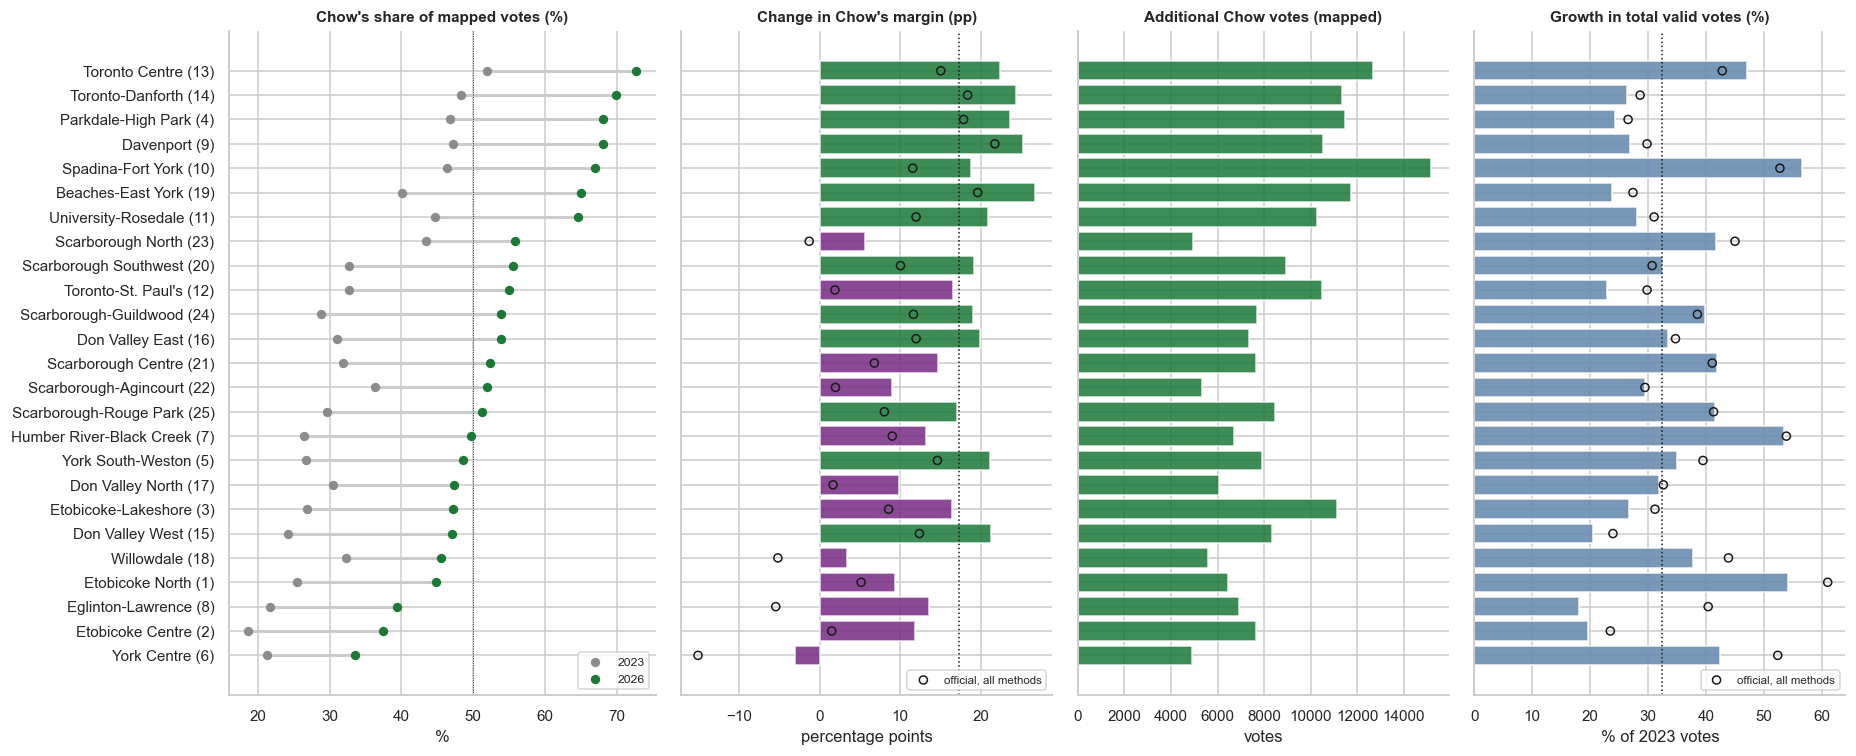

Tract-group (dominant-ward) vs. exact source ward totals, Chow 2026 share: mean |difference| 0.2 pp, max 1.4 pp (tracts straddle ward lines, so tract groups only approximate wards).
Wards with Chow above 50% of votes: mapped 2023 1, mapped 2026 15 | official all-method: 2023 2, 2026 15
d_margin {'lowest': ['York Centre (-3.0)', 'Willowdale (3.4)', 'Scarborough North (5.6)'], 'highest': ['Beaches-East York (26.8)', 'Davenport (25.3)', 'Toronto-Danforth (24.4)']}
add_chow {'lowest': ['York Centre (4,904.0)', 'Scarborough North (4,953.0)', 'Scarborough-Agincourt (5,325.0)'], 'highest': ['Spadina-Fort York (15,169.0)', 'Toronto Centre (12,689.0)', 'Beaches-East York (11,739.0)']}
g_valid {'lowest': ['Eglinton-Lawrence (18.1)', 'Etobicoke Centre (19.6)', 'Don Valley West (20.6)'], 'highest': ['Spadina-Fort York (56.6)', 'Etobicoke North (54.1)', 'Humber River-Black Creek (53.5)']}
lp26 {'lowest': ['Humber River-Black Creek (91.0)', 'Etobicoke North (91.4)', 'Scarborough North (91.6)'], 'hig

/tmp/ipykernel_1285106/2150461709.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  check = t.groupby("ward_dominant").apply(lambda d: d.chow_v26.sum() / d.valid26.sum() * 100).reindex(W.index)


In [17]:
def wtab(d, y): 
    x = d[y].copy(); x["chow_sh"] = x.chow / x.valid * 100; x["opp_sh"] = x.opp / x.valid * 100; x["margin"] = x.chow_sh - x.opp_sh; x["lp"] = x.chow_sh + x.opp_sh; x["pair"] = x.chow / (x.chow + x.opp) * 100
    return x
wm23, wm26, wo23, wo26 = wtab(MAPPED_SRC, 2023), wtab(MAPPED_SRC, 2026), wtab(OFFICIAL, 2023), wtab(OFFICIAL, 2026)
W = pd.DataFrame({"name": ward_names, "chow23": wm23.chow_sh, "chow26": wm26.chow_sh, "margin23": wm23.margin, "margin26": wm26.margin, "d_margin": wm26.margin - wm23.margin,
                  "d_margin_official": wo26.margin - wo23.margin, "add_chow": wm26.chow - wm23.chow, "g_valid": (wm26.valid / wm23.valid - 1) * 100,
                  "g_valid_official": (wo26.valid / wo23.valid - 1) * 100, "valid23": wm23.valid, "valid26": wm26.valid, "lp23": wm23.lp, "lp26": wm26.lp,
                  "chow_v23": wm23.chow, "chow_v26": wm26.chow, "opp_v23": wm23.opp, "opp_v26": wm26.opp, "pair23": wm23.pair, "pair26": wm26.pair}).sort_values("chow26")
lab = [f"{r['name']} ({i})" for i, r in W.iterrows()]
fig, ax = plt.subplots(1, 4, figsize=(17, 7), sharey=True, gridspec_kw={"width_ratios": [1.15, 1, 1, 1]})
ax[0].hlines(lab, W.chow23, W.chow26, color="#cccccc", lw=2); ax[0].scatter(W.chow23, lab, color=C23, s=26, zorder=3, label="2023"); ax[0].scatter(W.chow26, lab, color=C26, s=26, zorder=3, label="2026")
ax[0].axvline(50, color="k", lw=.6, ls=":"); ax[0].set(title="Chow's share of mapped votes (%)", xlabel="%"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].barh(lab, W.d_margin, color=np.where(W.d_margin >= W.d_margin.median(), CHOW, OPP), alpha=.85); ax[1].scatter(W.d_margin_official, lab, facecolors="none", edgecolors="k", s=28, zorder=3, label="official, all methods")
ax[1].axvline(P.d_margin, color="k", ls=":", lw=1); ax[1].set(title="Change in Chow's margin (pp)", xlabel="percentage points"); ax[1].legend(fontsize=7.5, loc="lower right")
ax[2].barh(lab, W.add_chow, color=CHOW, alpha=.85); ax[2].set(title="Additional Chow votes (mapped)", xlabel="votes")
ax[3].barh(lab, W.g_valid, color="#6a8caf", alpha=.9); ax[3].scatter(W.g_valid_official, lab, facecolors="none", edgecolors="k", s=28, zorder=3, label="official, all methods")
ax[3].axvline(P.g_valid, color="k", ls=":", lw=1); ax[3].set(title="Growth in total valid votes (%)", xlabel="% of 2023 votes"); ax[3].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()
check = t.groupby("ward_dominant").apply(lambda d: d.chow_v26.sum() / d.valid26.sum() * 100).reindex(W.index)
print(f"Tract-group (dominant-ward) vs. exact source ward totals, Chow 2026 share: mean |difference| {np.abs(check - W.chow26).mean():.1f} pp, max {np.abs(check - W.chow26).max():.1f} pp "
      "(tracts straddle ward lines, so tract groups only approximate wards).")
print(f"Wards with Chow above 50% of votes: mapped 2023 {(W.chow23 > 50).sum()}, mapped 2026 {(W.chow26 > 50).sum()} | official all-method: 2023 {(wo23.chow_sh > 50).sum()}, 2026 {(wo26.chow_sh > 50).sum()}")
def extremes(col, n=3):
    s_ = W[col].sort_values(); f = lambda ids: [f"{W.loc[i, 'name']} ({s_[i]:,.1f})" for i in ids]
    return {"lowest": f(s_.index[:n]), "highest": f(s_.index[::-1][:n])}
for col in ("d_margin", "add_chow", "g_valid", "lp26"):
    print(col, extremes(col))
print("Eglinton-Lawrence vote growth: mapped %.1f%%, official %.1f%%" % (W.loc[8, "g_valid"], W.loc[8, "g_valid_official"]))
print("Wards where the OFFICIAL all-method change in Chow's margin was negative:", [f"{W.loc[i, 'name']} ({W.loc[i, 'd_margin_official']:.1f})" for i in W.index[W.d_margin_official < 0]],
      "| where the mapped change was negative:", [W.loc[i, "name"] for i in W.index[W.d_margin < 0]])

**By ward (exact source totals).** On mapped votes Chow's share was above 50% in one ward in 2023 (Toronto Centre) and 15 in 2026 (official all-method: 2 and 15). Her margin gain ranged from −3.0 points in York Centre (the only ward where it fell) and +3.4 in Willowdale and +5.6 in Scarborough North, to +26.8 in Beaches-East York, +25.3 in Davenport and +24.4 in Toronto-Danforth. **The official all-method change is different:** the hollow markers show her margin falling in four wards (York Centre −15.1, Eglinton-Lawrence −5.5, Willowdale −5.2, Scarborough North −1.3), because her 2023 advance and mail-in vote there was strong. Ward vote growth differs between mapped and official votes too (Eglinton-Lawrence +18% mapped vs. +40% official), so ward volume figures should be read as growth in *mapped* votes. Highlights: wards with the lowest 2026 shares are York Centre, Etobicoke Centre and Eglinton-Lawrence; the smallest additional Chow votes are in York Centre (4,904), Scarborough North (4,953) and Scarborough-Agincourt (5,325); the largest in Spadina-Fort York (15,169), Toronto Centre (12,689) and Beaches-East York (11,739).

## 4. Votes and voting volume

Without an eligible-elector denominator, vote counts show **voting volume** in the mapped votes, not turnout. Context: official turnout for the 2023 by-election was about 37% of the final voters' list (724,638 votes on 1,947,242 electors, per the repository's audit of the City files); no equivalent verified 2026 denominator is available here. The 2023 contest was a stand-alone by-election; 2026 was a regular municipal election, so the volume comparison is not like-for-like.

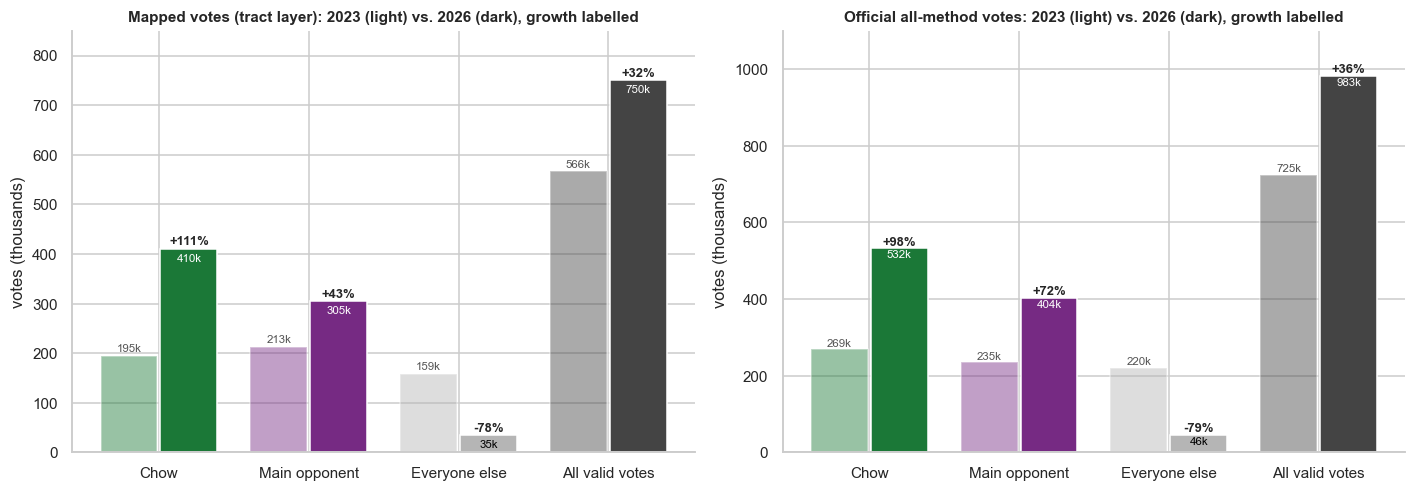

Mapped votes: Chow gained +215705 votes (+111%), the main opponent +92105 (+43%), total valid votes +183610 (+32%); Chow's vote lead moved from -18074 to +105526.
Official:     Chow +262829 (+98%), main opponent +168838 (+72%), total valid +258022 (+36%); Chow's lead moved from +34197 to +128188.


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for a, (ttl, c23, c26) in zip(ax, (("Mapped votes (tract layer)", layer_city[2023], layer_city[2026]), ("Official all-method votes", official_city[2023], official_city[2026]))):
    groups = [("Chow", c23["chow"], c26["chow"], CHOW), ("Main opponent", c23["opp"], c26["opp"], OPP),
              ("Everyone else", c23["valid"] - c23["chow"] - c23["opp"], c26["valid"] - c26["chow"] - c26["opp"], OTHER), ("All valid votes", c23["valid"], c26["valid"], "#444444")]
    for i, (nm, v23, v26, colr) in enumerate(groups):
        a.bar(i - .2, v23 / 1e3, width=.38, color=colr, alpha=.45); a.bar(i + .2, v26 / 1e3, width=.38, color=colr)
        a.text(i + .2, v26 / 1e3 + 8, f"{(v26 / v23 - 1) * 100:+.0f}%", ha="center", fontsize=8.5, fontweight="bold")
        a.text(i - .2, v23 / 1e3 + 8, f"{v23 / 1e3:.0f}k", ha="center", fontsize=7.5, color="#555"); a.text(i + .2, v26 / 1e3 - 25, f"{v26 / 1e3:.0f}k", ha="center", fontsize=7.5, color="white" if nm != "Everyone else" else "black")
    a.set_xticks(range(4)); a.set_xticklabels([g[0] for g in groups]); a.set(ylabel="votes (thousands)", title=ttl + ": 2023 (light) vs. 2026 (dark), growth labelled"); a.set_ylim(0, 1100 if "Official" in ttl else 850)
plt.tight_layout(); plt.show()
print("Mapped votes: Chow gained %+d votes (%+.0f%%), the main opponent %+d (%+.0f%%), total valid votes %+d (%+.0f%%); Chow's vote lead moved from %+d to %+d." %
      (P.d_chow_v, P.g_chow, P.d_opp_v, P.g_opp, P.d_valid, P.g_valid, P.lead_v23, P.lead_v26))
o23, o26 = official_city[2023], official_city[2026]
print("Official:     Chow %+d (%+.0f%%), main opponent %+d (%+.0f%%), total valid %+d (%+.0f%%); Chow's lead moved from %+d to %+d." %
      (o26.chow - o23.chow, (o26.chow / o23.chow - 1) * 100, o26.opp - o23.opp, (o26.opp / o23.opp - 1) * 100, o26.valid - o23.valid, (o26.valid / o23.valid - 1) * 100,
       o23.chow - o23.opp, o26.chow - o26.opp))

**Votes.** On mapped votes Chow gained 215,705 votes (+111%), her opponent 92,105 (+43%) and all valid votes 183,610 (+32%); the votes for all other candidates fell 78% (to 35k). Officially, Chow gained 262,829 (+98%), the main opponent 168,838 (+72%: Bailão 235,175 to Bradford 404,013) and total valid votes 258,022 (+36%). The mapped votes therefore overstate Chow's growth and understate her opponent's relative to the official totals. A candidate's vote count grew while their share did not necessarily: the opponent's votes rose 43% (mapped) while the opponent's share rose 3.1 points.

### 4.1 Local vote growth vs. share gains

Left: each tract's growth in all valid votes (horizontal) against growth in Chow's votes (vertical), on log scales with an equal-growth line. Because Chow's votes are her share times the total, **she grows faster than the total exactly when her share rises**, so the line is a restatement of "share rose" in count terms (every tract sits above it). The middle panel shows why raw additional votes are a poor guide to the strength of a shift: tract size drives them. Right: the same additional-vote figures against the share gain, with tract size shown by colour. Tracts under 300 valid votes in either election are shown faintly (percentage growth from tiny baselines is unstable).

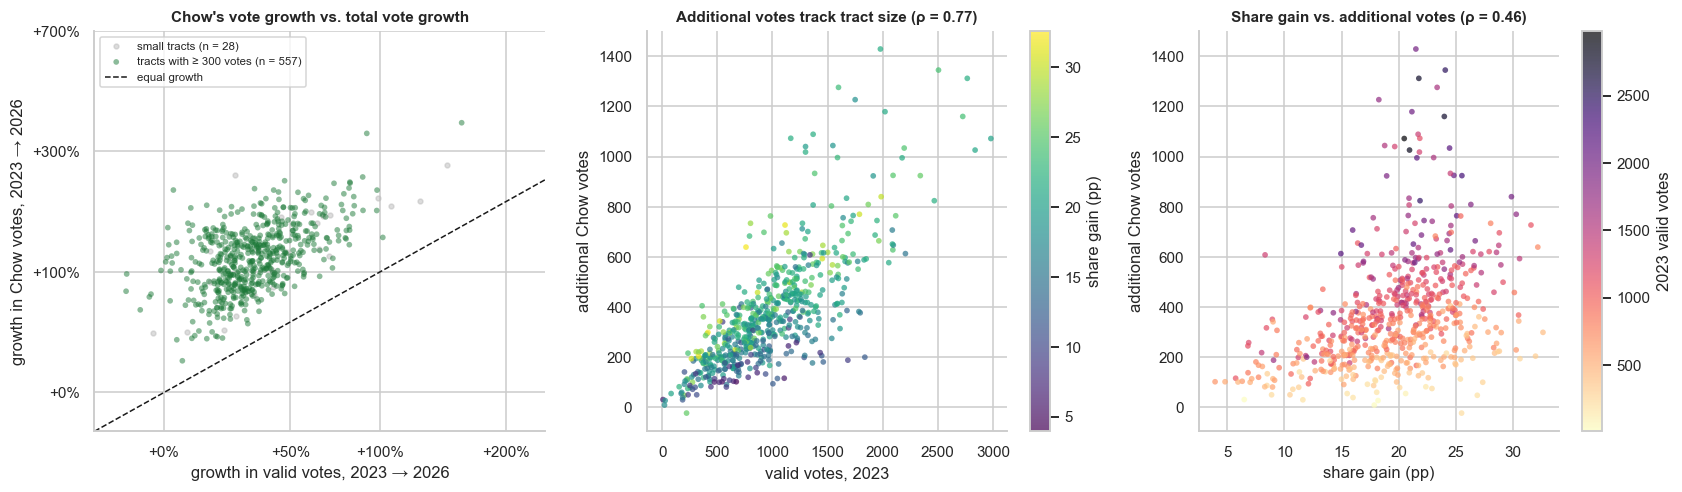

Total valid vote growth by tract: median 33%, middle half 22% to 45%, 8 tracts fell. Chow's votes grew faster than the total in 585 of 585 tracts.


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.6))
a = ax[0]; big = t.big
a.scatter((t.valid26 / t.valid23)[~big], (t.chow_v26 / t.chow_v23)[~big], s=10, color="#bbbbbb", alpha=.5, label=f"small tracts (n = {int((~big).sum())})")
a.scatter((t.valid26 / t.valid23)[big], (t.chow_v26 / t.chow_v23)[big], s=14, color=CHOW, alpha=.5, edgecolor="none", label=f"tracts with ≥ {MIN_VALID_VOTES} votes (n = {int(big.sum())})")
lim = [.8, 8]; a.plot(lim, lim, "k--", lw=1, label="equal growth"); a.set(xscale="log", yscale="log", xlim=(.8, 3.4), ylim=(.8, 8), xlabel="growth in valid votes, 2023 → 2026", ylabel="growth in Chow votes, 2023 → 2026", title="Chow's vote growth vs. total vote growth")
ticks = [1, 1.5, 2, 3]; a.set_xticks(ticks); a.set_xticklabels([f"{(x - 1) * 100:+.0f}%" for x in ticks]); a.set_yticks([1, 2, 4, 8]); a.set_yticklabels([f"{(y - 1) * 100:+.0f}%" for y in (1, 2, 4, 8)]); a.minorticks_off()
a.legend(fontsize=7.5, loc="upper left")
a = ax[1]; sc = a.scatter(t.valid23, t.d_chow_v, s=14, c=t.d_chow, cmap="viridis", alpha=.7, edgecolor="none"); plt.colorbar(sc, ax=a, label="share gain (pp)")
a.set(xlabel="valid votes, 2023", ylabel="additional Chow votes", title=f"Additional votes track tract size (ρ = {stats.spearmanr(t.valid23, t.d_chow_v)[0]:.2f})")
a = ax[2]; sc = a.scatter(t.d_chow, t.d_chow_v, s=14, c=t.valid23, cmap="magma_r", alpha=.7, edgecolor="none"); plt.colorbar(sc, ax=a, label="2023 valid votes")
a.set(xlabel="share gain (pp)", ylabel="additional Chow votes", title=f"Share gain vs. additional votes (ρ = {stats.spearmanr(t.d_chow, t.d_chow_v)[0]:.2f})")
plt.tight_layout(); plt.show()
print(f"Total valid vote growth by tract: median {t.g_valid.median():.0f}%, middle half {t.g_valid.quantile(.25):.0f}% to {t.g_valid.quantile(.75):.0f}%, {int((t.g_valid < 0).sum())} tracts fell. "
      f"Chow's votes grew faster than the total in {int((t.g_chow > t.g_valid).sum())} of 585 tracts.")

**Local volume vs. local share.** Median tract valid-vote growth was 33% (middle half 22-45%; 8 tracts fell), and Chow's votes grew faster than the total in every tract. Per the identity noted above, that is not a separate finding. The useful point is the middle and right panels: additional Chow votes depend heavily on how many votes the tract already had, which means large tracts dominate raw-gain maps and rankings and cannot be read as stronger shifts. The share-gain and margin-gain maps are the better guide to political change; the vote maps show where the votes are.

### 4.2 One accounting benchmark

How many votes would Chow have had in 2026 if her **2023 tract share had stayed constant** while the number of valid votes changed? The gap between that benchmark and her actual estimated votes is, by arithmetic, the share gain times the 2026 votes: Chow's additional votes split exactly into a **volume term** (more votes cast at her 2023 share) and a **share term** (a higher share of the 2026 votes). This is descriptive arithmetic; it does not identify new voters, converts, or causes. The split depends on the order of the terms, so the alternative ordering is shown too.

,Chow votes 2023,benchmark 2026 (2023 share held),actual 2026,volume term,share term,"volume term, other ordering","share term, other ordering"
mapped (tract sums),194656,257758,410361,63102,152603,100461,115244
official (citywide share),269372,365287,532201,95915,166914,139743,123086


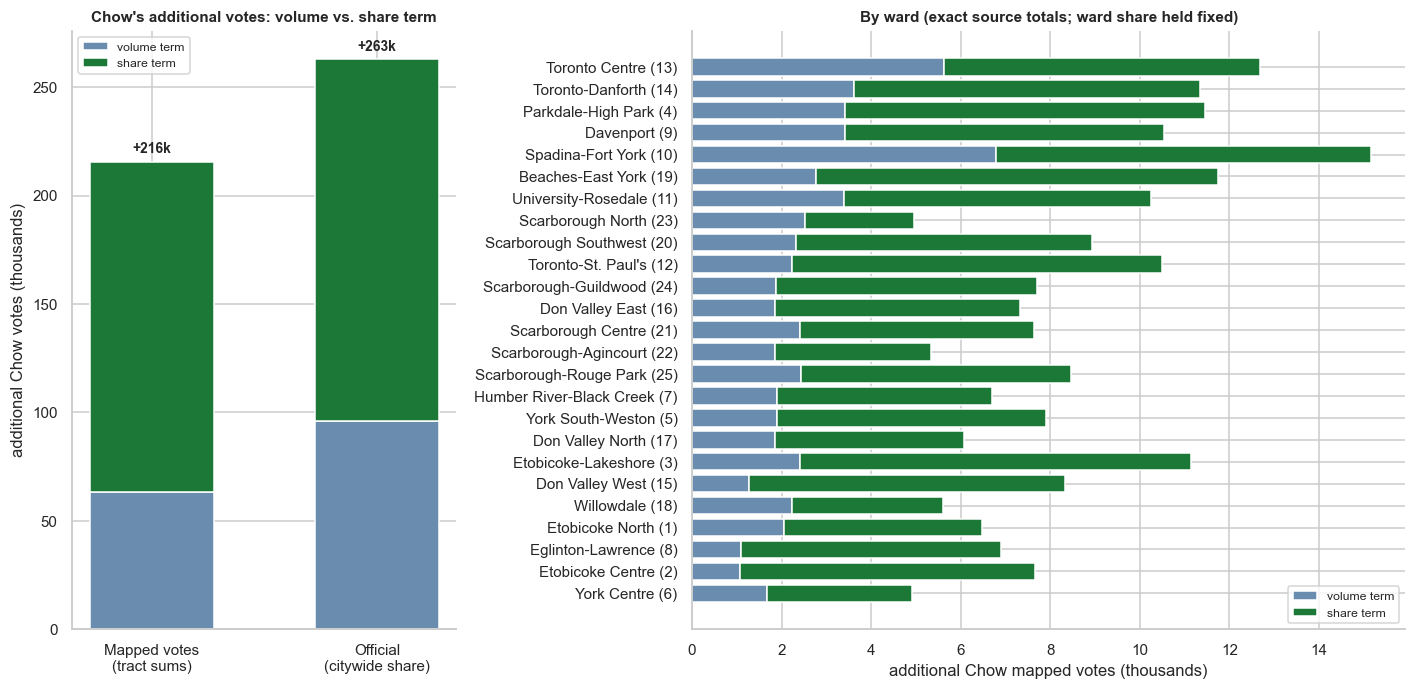

Share-term votes by tract: every one of 585 tracts increased


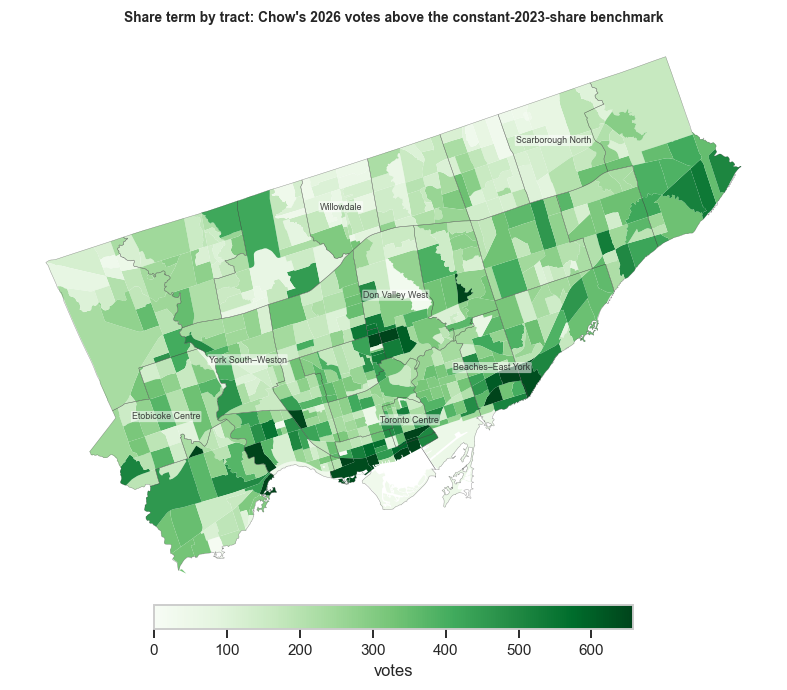

In [20]:
Wt = W.copy()
Wt["volume_term"] = (Wt.valid26 - Wt.valid23) * Wt.chow_v23 / Wt.valid23             # ward totals (exact source), 2023 ward share held fixed
Wt["share_term"] = Wt.chow_v26 - Wt.chow_v23 - Wt["volume_term"]
v23, v26 = np.array([t.valid23.sum(), o23.valid]), np.array([t.valid26.sum(), o26.valid])
c23_, c26_ = np.array([t.chow_v23.sum(), o23.chow]), np.array([t.chow_v26.sum(), o26.chow])
bench_city = pd.DataFrame({"Chow votes 2023": c23_, "benchmark 2026 (2023 share held)": c23_ / v23 * v26, "actual 2026": c26_}, index=["mapped (tract sums)", "official (citywide share)"])
bench_city["volume term"] = bench_city["benchmark 2026 (2023 share held)"] - bench_city["Chow votes 2023"]
bench_city["share term"] = bench_city["actual 2026"] - bench_city["benchmark 2026 (2023 share held)"]
bench_city["volume term, other ordering"] = (v26 - v23) * c26_ / v26                  # more votes valued at the 2026 share
bench_city["share term, other ordering"] = v23 * (c26_ / v26 - c23_ / v23)             # share change valued at 2023 votes
display(bench_city.round(0).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(13, 6.4), gridspec_kw={"width_ratios": [.7, 1.3]})
a = ax[0]
for i, (nm, r) in enumerate(bench_city.iterrows()):
    a.bar(i, r["volume term"] / 1e3, color="#6a8caf", width=.55, label="volume term" if i == 0 else None)
    a.bar(i, r["share term"] / 1e3, bottom=r["volume term"] / 1e3, color=CHOW, width=.55, label="share term" if i == 0 else None)
    a.text(i, (r["volume term"] + r["share term"]) / 1e3 + 4, f"+{(r['volume term'] + r['share term']) / 1e3:.0f}k", ha="center", fontsize=9, fontweight="bold")
a.set_xticks([0, 1]); a.set_xticklabels(["Mapped votes\n(tract sums)", "Official\n(citywide share)"]); a.set(ylabel="additional Chow votes (thousands)", title="Chow's additional votes: volume vs. share term"); a.legend(fontsize=8, loc="upper left")
a = ax[1]; Ws = Wt.sort_values("chow26"); labs = [f"{r['name']} ({i})" for i, r in Ws.iterrows()]
a.barh(labs, Ws.volume_term / 1e3, color="#6a8caf", label="volume term"); a.barh(labs, Ws.share_term / 1e3, left=Ws.volume_term / 1e3, color=CHOW, label="share term")
a.set(xlabel="additional Chow mapped votes (thousands)", title="By ward (exact source totals; ward share held fixed)"); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
cm_b, nm_b, note_b = change_scale(t.share_term); print("Share-term votes by tract:", note_b)
map_row([dict(col="share_term", cmap=cm_b, norm=nm_b, title="Share term by tract: Chow's 2026 votes above the constant-2023-share benchmark", unit="votes")], figsize=(8.5, 6.4))

**Accounting benchmark.** Had Chow's 2023 tract shares held while valid mapped votes grew, she would have had about 257,758 mapped votes in 2026 rather than 410,361. Her 215,705 additional votes then split into **63,102 from more votes cast (29%) and 152,603 from the higher share (71%)**; ordering the terms the other way gives 100,461 and 115,244 (47% / 53%). Official totals tell the same sort of story (volume 95,915 / share 166,914, or 139,743 / 123,086 the other way). So the share rise accounts for roughly half to 70% of her additional votes and the growth in votes cast for the rest; the split depends on the convention. It is arithmetic, not evidence about who the new voters were. By ward, the share term is largest in the downtown and east-end wards and relatively small in Scarborough North, Willowdale, York Centre and Scarborough-Agincourt.

### 4.3 Where did the additional votes come from?

Each ward's share of the city's **net additional Chow votes** (bars) against its share of the 2023 mapped vote (dots). A ward whose bar is longer than its dot contributed more than its 2023 weight.

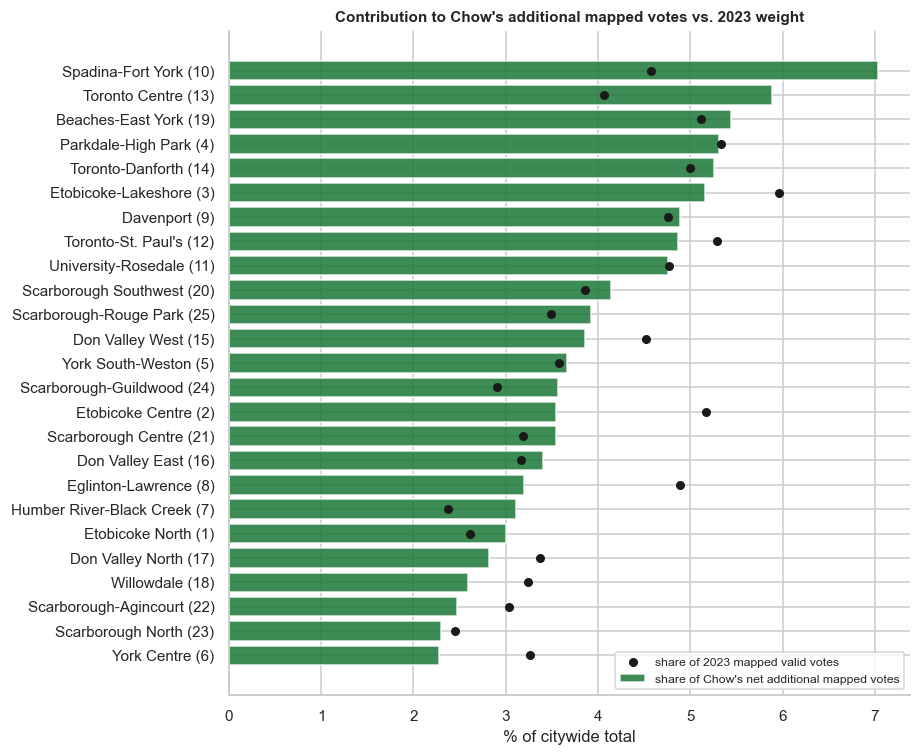

Five wards contributing the most: Spadina-Fort York (7.0%), Toronto Centre (5.9%), Beaches-East York (5.4%), Parkdale-High Park (5.3%), Toronto-Danforth (5.3%)


In [21]:
Wc = W.copy(); Wc["contrib"] = Wc.add_chow / Wc.add_chow.sum() * 100; Wc["base"] = Wc.valid23 / Wc.valid23.sum() * 100
Wc = Wc.sort_values("contrib"); labs = [f"{r['name']} ({i})" for i, r in Wc.iterrows()]
fig, ax = plt.subplots(figsize=(8.5, 7)); ax.barh(labs, Wc.contrib, color=CHOW, alpha=.85, label="share of Chow's net additional mapped votes")
ax.scatter(Wc.base, labs, color="k", s=24, zorder=3, label="share of 2023 mapped valid votes"); ax.set(xlabel="% of citywide total", title="Contribution to Chow's additional mapped votes vs. 2023 weight")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
print("Five wards contributing the most: " + ", ".join(f"{r['name']} ({r['contrib']:.1f}%)" for _, r in Wc.tail(5).iloc[::-1].iterrows()))

**Contribution to Chow's net additional votes.** Five wards supplied 29% of her additional mapped votes (Spadina-Fort York 7.0%, Toronto Centre 5.9%, Beaches-East York 5.4%, Parkdale-High Park 5.3%, Toronto-Danforth 5.3%), several by more than their 2023 weight. The biggest shortfalls against 2023 weight are Etobicoke Centre (3.5% vs. 5.2%), Eglinton-Lawrence (3.2% vs. 4.9%), Etobicoke-Lakeshore (5.2% vs. 6.0%) and Don Valley West (3.9% vs. 4.5%): wards where mapped votes also grew least (18-21% in Eglinton-Lawrence, Etobicoke Centre and Don Valley West) and where her margin gains were below average.

## 5. Consolidation around the two leaders

**Definition.** Consolidation is measured around the *same citywide leading pair* in each election (Chow + Bailão in 2023, Chow + Bradford in 2026), **not** the top two candidates tract by tract. The **leading-pair share** is their combined share of all valid votes; "all others" is the rest. Chow's share of all votes can be written as *leading-pair share × her share of the pair*. That matters because her share of all votes can rise a lot when the field contracts even if her position against her opponent changes little, and the reverse. Neither is a record of where individual voters went.

In [22]:
rows = {"Chow + main opponent (% of valid votes)": [P.lp23, P.lp26, (o23.chow + o23.opp) / o23.valid * 100, (o26.chow + o26.opp) / o26.valid * 100]}
rows["All other candidates (%)"] = [100 - v for v in rows["Chow + main opponent (% of valid votes)"]]
rows["Chow's share of the pair (%)"] = [P.pair23, P.pair26, o23.chow / (o23.chow + o23.opp) * 100, o26.chow / (o26.chow + o26.opp) * 100]
cons = pd.DataFrame(rows, index=["2023 mapped", "2026 mapped", "2023 official", "2026 official"]).T
cons["change, mapped"] = cons["2026 mapped"] - cons["2023 mapped"]; cons["change, official"] = cons["2026 official"] - cons["2023 official"]
display(cons.round(1))
q = lambda s: s.quantile([0, .05, .25, .5, .75, .95, 1]).round(1).tolist()
print("Tract leading-pair share, percentiles (min, 5, 25, 50, 75, 95, max): 2023", q(t.lp23), "| 2026", q(t.lp26))
print("Change in leading-pair share by tract: median %.1f, range %.1f to %.1f pp; increased in %d of 585 tracts" % (t.d_lp.median(), t.d_lp.min(), t.d_lp.max(), (t.d_lp > 0).sum()))

,2023 mapped,2026 mapped,2023 official,2026 official,"change, mapped","change, official"
Chow + main opponent (% of valid votes),71.90,95.40,69.60,95.30,23.40,25.60
All other candidates (%),28.10,4.60,30.40,4.70,-23.40,-25.60
Chow's share of the pair (%),47.80,57.40,53.40,56.80,9.60,3.50


Tract leading-pair share, percentiles (min, 5, 25, 50, 75, 95, max): 2023 [51.0, 59.5, 66.9, 71.9, 76.0, 80.4, 100.0] | 2026 [79.3, 90.1, 93.5, 95.7, 97.1, 98.1, 100.0]
Change in leading-pair share by tract: median 23.7, range -10.9 to 39.6 pp; increased in 584 of 585 tracts


**How much consolidation?** The leading pair's combined share rose from 71.9% to 95.4% of mapped votes (official: 69.6% to 95.3%), a rise of 23.4 points (25.6 officially). It is **not** "almost 100%" everywhere: in 2026 the median tract is at 95.7%, but the 5th percentile is 90.1% and the lowest tract 79.3%; in 2023 the middle was 71.9% (51% to 100%). Chow's share of the pair moved much less on official totals (+3.5) than on mapped (+9.6).

Change in leading-pair share: 1 of 585 tracts decreased


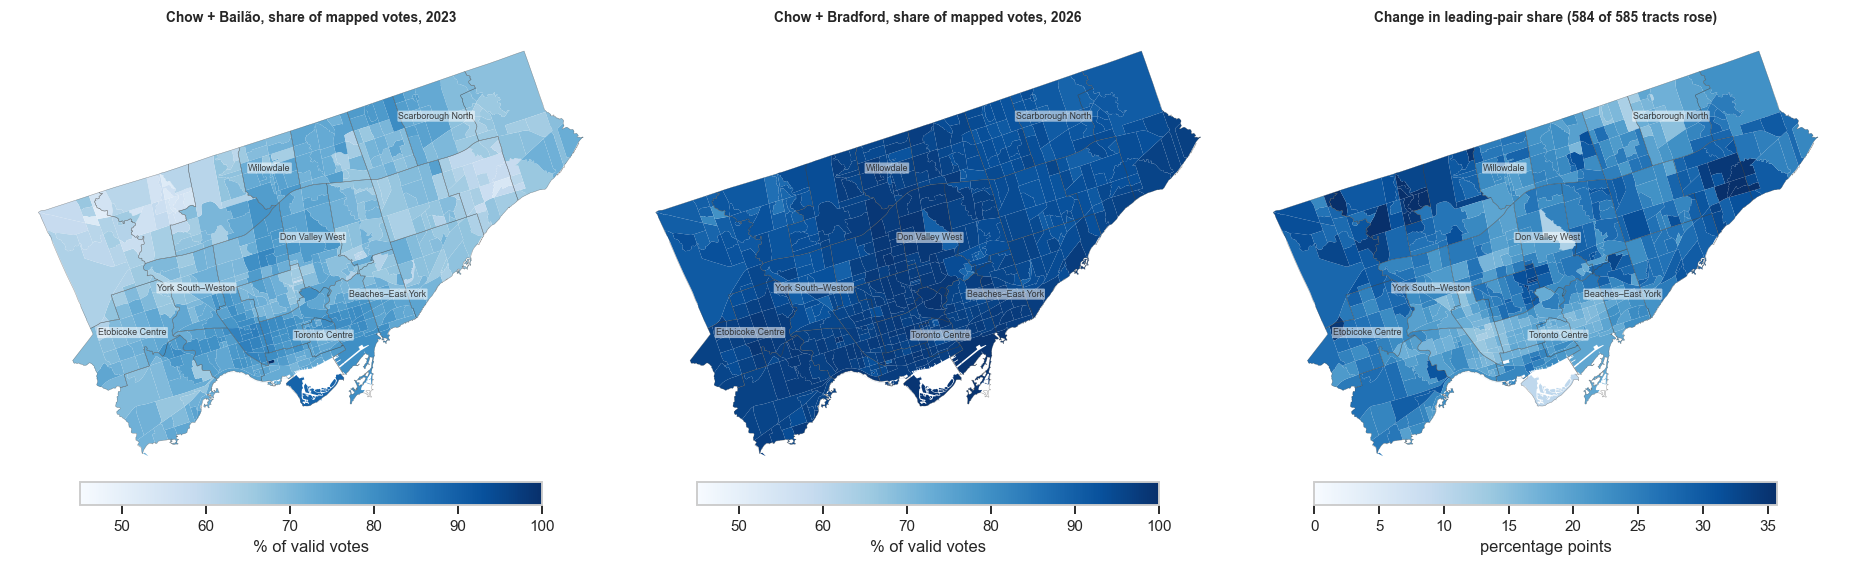

In [23]:
cmap_l, norm_l, note_l = change_scale(t.d_lp); print("Change in leading-pair share:", note_l)
map_row([dict(col="lp23", cmap="Blues", norm=Normalize(45, 100), title="Chow + Bailão, share of mapped votes, 2023", unit="% of valid votes"),
         dict(col="lp26", cmap="Blues", norm=Normalize(45, 100), title="Chow + Bradford, share of mapped votes, 2026", unit="% of valid votes"),
         dict(col="d_lp", cmap="Blues", norm=Normalize(0, np.nanpercentile(t.d_lp, 98)), title=f"Change in leading-pair share ({int((t.d_lp > 0).sum())} of 585 tracts rose)", unit="percentage points")])

**Where consolidation was greatest.** In 2023 the leading pair held the smallest shares in the north-west and a belt through the west and north, and the largest in the downtown core; by 2026 the pair has 90%+ almost everywhere. Because the starting point was lowest in the north-west, north and Scarborough, the largest rises (up to 35+ points) are there; consolidation rose least in the downtown core where it began higher, and one tract fell (−10.9 points).

### 5.1 Where consolidation was greatest, and how Chow's gain splits

Left: tract distributions of the leading-pair share. Middle: exact ward totals (mapped votes). Right: for each ward, Chow's share gain split into a **field-contraction term** (change in leading-pair share, valued at the average of her 2023 and 2026 pair share) and a **position term** (change in her share of the pair, valued at the average leading-pair share). The two add up exactly to her gain and the average-of-orderings choice is symmetric, but the split still depends on that convention (both ordering variants for the whole city follow below). It is arithmetic, not a causal decomposition.

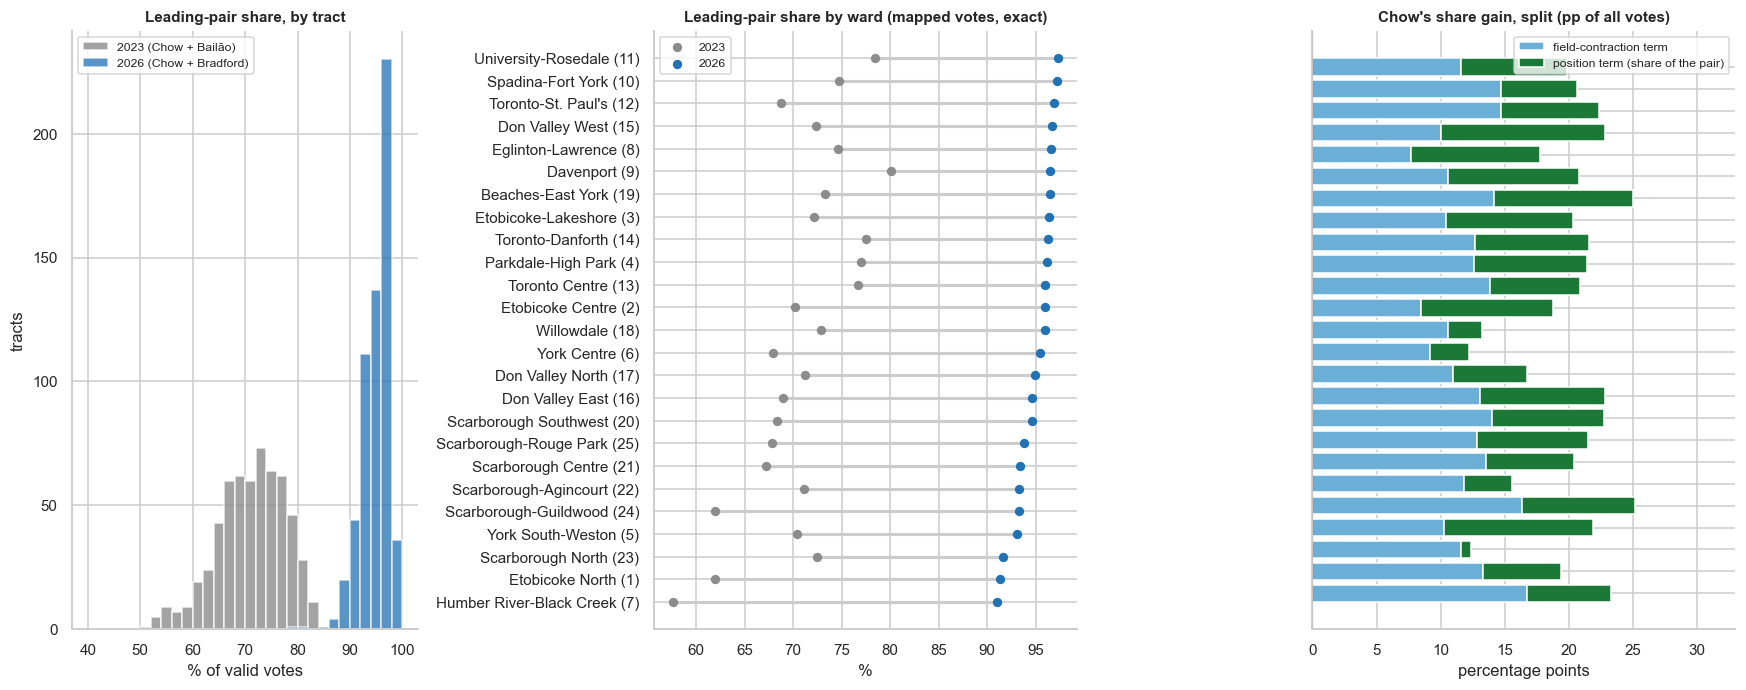

Citywide split of Chow's gain in share of all votes (percentage points)


,mapped (tract sums),official all methods
"field-contraction, field first",11.20,13.70
"position, field first",9.20,3.30
"field-contraction, position first",13.40,14.60
"position, position first",6.90,2.40
"field-contraction, symmetric",12.30,14.10
"position, symmetric",8.00,2.90
total Chow share gain,20.30,17.00


contraction term by ward: lowest ['Eglinton-Lawrence (7.7)', 'Etobicoke Centre (8.4)', 'York Centre (9.1)'] | highest ['Humber River-Black Creek (16.7)', 'Scarborough-Guildwood (16.3)', 'Spadina-Fort York (14.7)']
position term by ward: lowest ['Scarborough North (0.8)', 'Willowdale (2.7)', 'York Centre (3.1)'] | highest ['Don Valley West (12.8)', 'York South-Weston (11.7)', 'Beaches-East York (10.8)']


In [24]:
Wk = W.copy()
Wk["contraction"] = (Wk.lp26 - Wk.lp23) * (Wk.pair23 + Wk.pair26) / 2 / 100
Wk["position"] = (Wk.pair26 - Wk.pair23) * (Wk.lp23 + Wk.lp26) / 2 / 100
assert np.allclose(Wk.contraction + Wk.position, Wk.chow26 - Wk.chow23)
Wk = Wk.sort_values("lp26")
labk = [f"{r['name']} ({i})" for i, r in Wk.iterrows()]
fig, ax = plt.subplots(1, 3, figsize=(16, 6.4), gridspec_kw={"width_ratios": [.9, 1.1, 1.1]})
a = ax[0]; a.hist(t.lp23, bins=np.arange(40, 101, 2), color=C23, alpha=.8, label="2023 (Chow + Bailão)"); a.hist(t.lp26, bins=np.arange(40, 101, 2), color="#2171b5", alpha=.75, label="2026 (Chow + Bradford)")
a.set(title="Leading-pair share, by tract", xlabel="% of valid votes", ylabel="tracts"); a.legend(fontsize=8, loc="upper left")
a = ax[1]; a.hlines(labk, Wk.lp23, Wk.lp26, color="#cccccc", lw=2); a.scatter(Wk.lp23, labk, color=C23, s=26, zorder=3, label="2023"); a.scatter(Wk.lp26, labk, color="#2171b5", s=26, zorder=3, label="2026")
a.set(title="Leading-pair share by ward (mapped votes, exact)", xlabel="%"); a.legend(fontsize=8, loc="upper left")
a = ax[2]; a.barh(labk, Wk.contraction, color="#6baed6", label="field-contraction term"); a.barh(labk, Wk.position, left=Wk.contraction, color=CHOW, label="position term (share of the pair)")
a.axvline(0, color="k", lw=.7); a.set_yticklabels([]); a.set(title="Chow's share gain, split (pp of all votes)", xlabel="percentage points", xlim=(0, 33)); a.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

def split(lp23, lp26, p23, p26):
    return {"field-contraction, field first": (lp26 - lp23) * p23 / 100, "position, field first": (p26 - p23) * lp26 / 100,
            "field-contraction, position first": (lp26 - lp23) * p26 / 100, "position, position first": (p26 - p23) * lp23 / 100,
            "field-contraction, symmetric": (lp26 - lp23) * (p23 + p26) / 200, "position, symmetric": (p26 - p23) * (lp23 + lp26) / 200, "total Chow share gain": (lp26 * p26 - lp23 * p23) / 100}
dec = pd.DataFrame({"mapped (tract sums)": split(P.lp23, P.lp26, P.pair23, P.pair26),
                    "official all methods": split(cons.loc["Chow + main opponent (% of valid votes)", "2023 official"], cons.loc["Chow + main opponent (% of valid votes)", "2026 official"],
                                                  cons.loc["Chow's share of the pair (%)", "2023 official"], cons.loc["Chow's share of the pair (%)", "2026 official"])})
print("Citywide split of Chow's gain in share of all votes (percentage points)"); display(dec.round(1))
for col in ("contraction", "position"):
    s_ = Wk[col].sort_values(); print(f"{col} term by ward: lowest", [f"{Wk.loc[i, 'name']} ({s_[i]:.1f})" for i in s_.index[:3]], "| highest", [f"{Wk.loc[i, 'name']} ({s_[i]:.1f})" for i in s_.index[::-1][:3]])

**Ward view and accounting.** Ward leading-pair shares in 2026 ranged from 91.0% (Humber River-Black Creek) to 97.3% (University-Rosedale), and 2023 shares from about 62% to 80%. Splitting Chow's gain into a field-contraction part and a position-in-the-pair part (right panel) gives, citywide on **mapped votes**, 12.3 points from contraction and 8.0 from position (61% / 39%; contraction between 11.2 and 13.4 depending on ordering). On **official** totals it is 14.1 and 2.9 (83% / 17%; contraction 13.7 to 14.6). So under this accounting the field contracting is the larger part of Chow's share gain in both cases, a clear majority on official numbers and a moderate one on mapped numbers. By ward, the position term is largest in Don Valley West (12.8 points), York South-Weston (11.7) and Beaches-East York (10.8) and smallest in Scarborough North (0.8), Willowdale (2.7) and York Centre (3.1), while the contraction term is largest in Humber River-Black Creek (16.7), Scarborough-Guildwood (16.3) and Spadina-Fort York (14.7) and smallest in Eglinton-Lawrence (7.7), Etobicoke Centre (8.4) and York Centre (9.1). This is arithmetic and does not say where any individual vote came from.

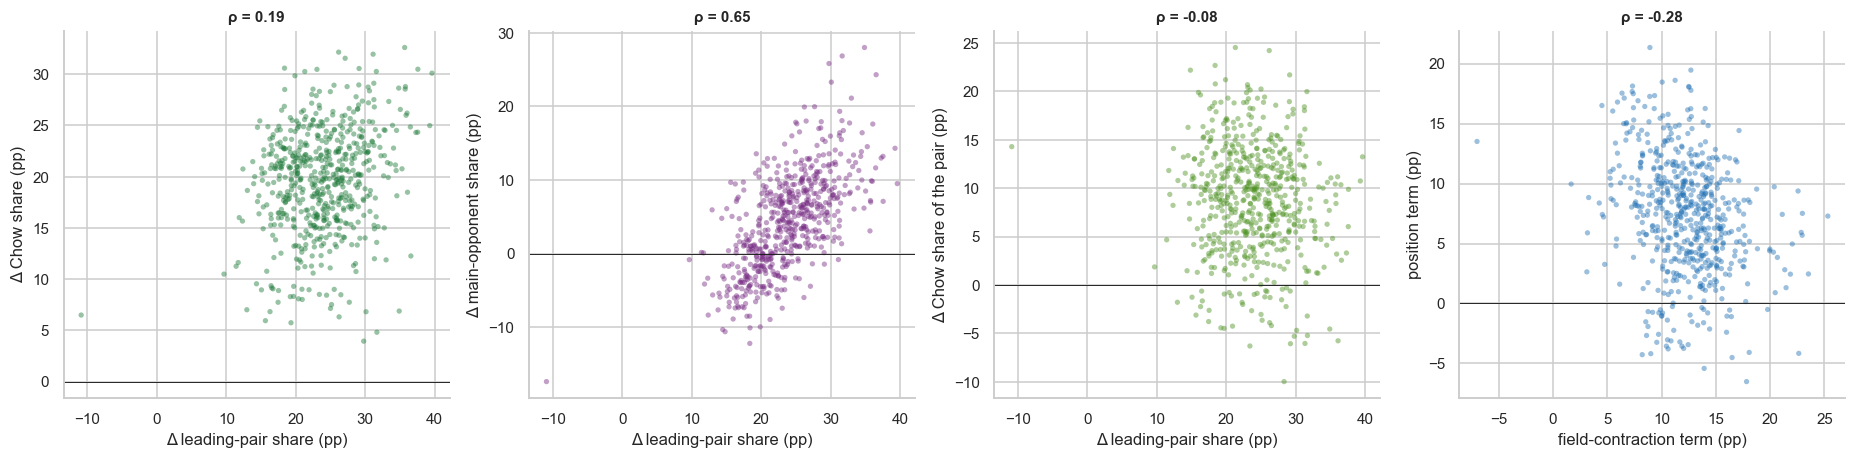

Tract-level terms (pp of all votes): field-contraction mean 12.2 (SD 3.5), position mean 7.3 (SD 4.8); position term negative in 43 tracts, contraction term negative in 1


In [25]:
t["contraction"] = t.d_lp * (t.pair23 + t.pair26) / 200; t["position"] = t.d_pair * (t.lp23 + t.lp26) / 200
assert np.allclose(t.contraction + t.position, t.d_chow)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
for a, (x, y, xl, yl, colr) in zip(ax, (("d_lp", "d_chow", "Δ leading-pair share (pp)", "Δ Chow share (pp)", CHOW), ("d_lp", "d_opp", "Δ leading-pair share (pp)", "Δ main-opponent share (pp)", OPP),
                                       ("d_lp", "d_pair", "Δ leading-pair share (pp)", "Δ Chow share of the pair (pp)", "#4d9221"), ("contraction", "position", "field-contraction term (pp)", "position term (pp)", "#2171b5"))):
    a.scatter(t[x], t[y], s=12, alpha=.45, color=colr, edgecolor="none"); a.axhline(0, color="k", lw=.6)
    a.set(xlabel=xl, ylabel=yl, title=f"ρ = {stats.spearmanr(t[x], t[y])[0]:.2f}")
plt.tight_layout(); plt.show()
print("Tract-level terms (pp of all votes): field-contraction mean %.1f (SD %.1f), position mean %.1f (SD %.1f); position term negative in %d tracts, contraction term negative in %d" %
      (t.contraction.mean(), t.contraction.std(), t.position.mean(), t.position.std(), (t.position < 0).sum(), (t.contraction < 0).sum()))

**Does more consolidation mean bigger gains?** Tracts with a larger rise in leading-pair share did not have systematically bigger Chow gains (ρ = 0.19) or larger changes in her share of the pair (ρ = −0.08), but they did have bigger rises in the opponent's share (ρ = 0.65). Part of this is mechanical: the leading pair's change is the sum of the two candidates' changes, and Chow's share rose in a fairly narrow band everywhere. The right-hand panel shows the two parts of Chow's gain across tracts: the contraction term varies little (mean 12.2, SD 3.5) compared with the position term (mean 7.3, SD 4.8; negative in 43 tracts). The upshot: the field contraction lifted Chow similarly everywhere, and where she did better or worse against her opponent depended on the position term.

### 5.2 Consolidation across neighbourhood types

The leading-pair share in 2023 and 2026 for each fifth of tracts (pooled votes) on four census variables. Quintile ranges are in the labels.

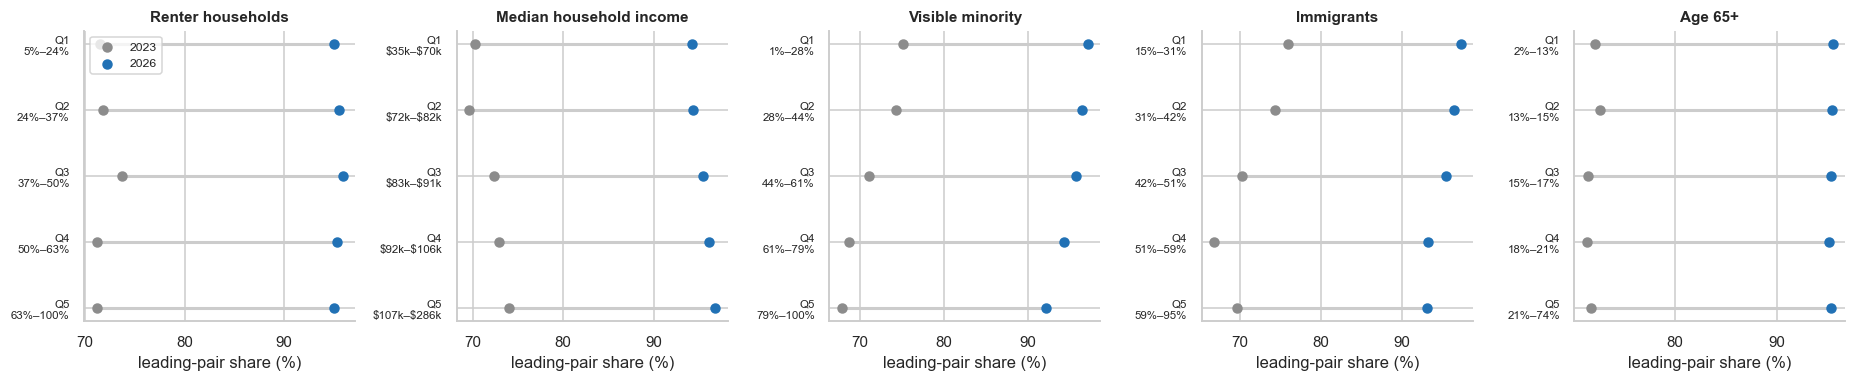

Leading-pair share, (Q1 2023, Q5 2023, Q1 2026, Q5 2026): {'Renter households': (np.float64(71.6), np.float64(71.2), np.float64(95.0), np.float64(95.0)), 'Median household income': (np.float64(70.3), np.float64(74.0), np.float64(94.2), np.float64(96.8)), 'Visible minority': (np.float64(75.2), np.float64(67.8), np.float64(97.1), np.float64(92.2)), 'Immigrants': (np.float64(75.9), np.float64(69.6), np.float64(97.3), np.float64(93.1)), 'Age 65+': (np.float64(72.2), np.float64(71.8), np.float64(95.5), np.float64(95.4))}


In [26]:
FMT = {"hhtnrent_pct": lambda v: f"{v * 100:.0f}%", "vminvisi_pct": lambda v: f"{v * 100:.0f}%", "imstimmi_pct": lambda v: f"{v * 100:.0f}%", "agec065p_pct": lambda v: f"{v * 100:.0f}%",
       "edcauniv_pct": lambda v: f"{v * 100:.0f}%", "agec2029_pct": lambda v: f"{v * 100:.0f}%", "ihat_med__nc": lambda v: f"\\${v / 1e3:.0f}k", "popdsqkm__nc": lambda v: f"{v / 1e3:.1f}k"}

def quintile_profile(var):
    d = t.dropna(subset=[var]).copy(); d["q"] = pd.qcut(d[var], 5, labels=False) + 1
    rows = []
    for k, g in d.groupby("q"):
        r = pooled(g); r["q"], r["lo"], r["hi"] = k, g[var].min(), g[var].max(); r["tick"] = f"Q{k}\n{FMT[var](r['lo'])}–{FMT[var](r['hi'])}"; rows.append(r)
    return pd.DataFrame(rows)

QV = {"hhtnrent_pct": "Renter households", "ihat_med__nc": "Median household income", "vminvisi_pct": "Visible minority", "imstimmi_pct": "Immigrants", "agec065p_pct": "Age 65+"}
QP = {v: quintile_profile(v) for v in QV}
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, (v, nm) in zip(ax, QV.items()):
    d = QP[v]; a.hlines(d.q, d.lp23, d.lp26, color="#cccccc", lw=2); a.scatter(d.lp23, d.q, color=C23, s=34, zorder=3, label="2023"); a.scatter(d.lp26, d.q, color="#2171b5", s=34, zorder=3, label="2026")
    a.set_yticks(d.q); a.set_yticklabels(d.tick, fontsize=7.5); a.set_title(nm); a.set_xlabel("leading-pair share (%)"); a.invert_yaxis()
ax[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()
print("Leading-pair share, (Q1 2023, Q5 2023, Q1 2026, Q5 2026):", {nm: tuple(round(QP[v][c].iloc[i], 1) for c, i in (("lp23", 0), ("lp23", -1), ("lp26", 0), ("lp26", -1))) for v, nm in QV.items()})

**Consolidation by neighbourhood type.** In 2026 the leading pair held more of the vote in tracts with fewer visible-minority residents (97.1% in the lowest fifth vs. 92.2% in the highest) and fewer immigrants (97.3% vs. 93.1%), and slightly more in higher-income tracts (94.2% lowest fifth vs. 96.8% highest). There is no gradient by renter share (95.0% in both extremes) or age 65+. The same direction held in 2023 (75.2% vs. 67.8% by visible minority), with the gap narrowing from about 7 to 5 points as every group consolidated.

## 6. Neighbourhood demographics

### 6.1 The census variables

All are 2021 census-tract measures from the project's census table (Statistics Canada data compiled upstream by Zack Taylor's Toronto elections mapper; labels and universes below come from the repository's own metadata). A "% X" is a share of the universe named in the table, so it describes residents of the tract.

**Income caveat.** The metadata labels `ihat_med__nc` "Median Household Income" with unit "dollars" and nothing more: the repository does not document the income reference year, price basis or exact census characteristic. I therefore use it only as a **ranking of tracts (quintiles, correlations)** and do not interpret dollar amounts as precise or as a particular year's income.

In [27]:
meta = json.load(open(CENSUS_META)); by_id = {v["id"]: v for v in meta["variables"]}; by_nom = {v["nom"]: v for v in meta["variables"] if v.get("nom")}
rows = []
for col, name in PRIMARY.items():
    v = by_id.get(col) or by_nom.get(col)
    rows.append({"variable": name, "column": col, "universe / unit": v.get("den_label") if v.get("kind") == "pct" else v.get("unit"), "census years in source": f"{min(v['years'])}-{max(v['years'])}",
                 "tract median": t[col].median(), "missing tracts": int(t[col].isna().sum())})
display(pd.DataFrame(rows).set_index("variable").round(2))

,column,universe / unit,census years in source,tract median,missing tracts
variable,,,,,
Renter households,hhtnrent_pct,Dwellings - Tenure - Total,1996-2021,0.43,2
Median household income,ihat_med__nc,dollars,1996-2021,"86,000.00",2
Visible minority,vminvisi_pct,Visible Minority - Total,1996-2021,0.53,2
Immigrants,imstimmi_pct,Immigrant Status - Total,1996-2021,0.47,2
University degree,edcauniv_pct,Educational Attainment - Total,1996-2021,0.39,2
Age 20-29,agec2029_pct,Population by Age - Total,1996-2021,0.14,0
Age 65+,agec065p_pct,Population by Age - Total,1996-2021,0.17,0
Apartment dwellings,dwtpapt__pct,Dwellings - Type - Total,1996-2021,0.52,0
Transit commuters,jwmdtran_pct,Commute - Total,1996-2021,0.25,2


### 6.2 Overview: which variables go with which outcomes

Pearson (left) and Spearman (right) correlations across the 583-585 tracts with data, for Chow's share in each election and for the changes. These are descriptive summaries of association between places; the strongest tell us where to look, and several variables measure overlapping things (density, apartments, renters and transit commuting are correlated with each other).

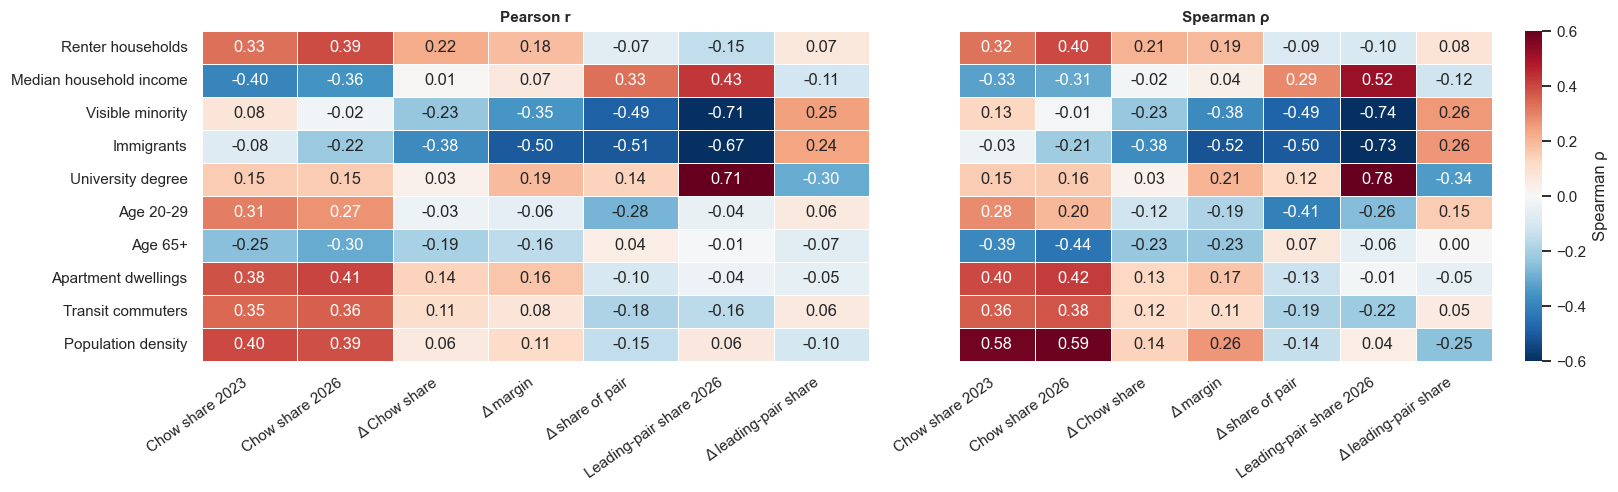

Correlations among the predictors themselves (Spearman), selected: {'Renter households / Apartment dwellings': np.float64(0.77), 'Renter households / Population density': np.float64(0.59), 'Visible minority / Immigrants': np.float64(0.9), 'Renter households / Median household income': np.float64(-0.71)}


In [28]:
OUT = {"chow23": "Chow share 2023", "chow26": "Chow share 2026", "d_chow": "Δ Chow share", "d_margin": "Δ margin", "d_pair": "Δ share of pair", "lp26": "Leading-pair share 2026", "d_lp": "Δ leading-pair share"}
def corr_matrix(method):
    return pd.DataFrame({OUT[o]: {PRIMARY[p]: t[[o, p]].dropna().corr(method=method).iloc[0, 1] for p in PRIMARY} for o in OUT})
cp_, cs_ = corr_matrix("pearson"), corr_matrix("spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a, (m_, nm) in zip(ax, ((cp_, "Pearson r"), (cs_, "Spearman ρ"))):
    sns.heatmap(m_, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, ax=a, linewidths=.4, cbar=a is ax[1], cbar_kws={"label": nm} if a is ax[1] else None)
    a.set_title(nm); a.set_xticklabels(a.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout(); plt.show()
print("Correlations among the predictors themselves (Spearman), selected:",
      {f"{PRIMARY[a]} / {PRIMARY[b]}": round(t[[a, b]].corr(method='spearman').iloc[0, 1], 2) for a, b in (("hhtnrent_pct", "dwtpapt__pct"), ("hhtnrent_pct", "popdsqkm__nc"), ("vminvisi_pct", "imstimmi_pct"), ("hhtnrent_pct", "ihat_med__nc"))})

**Overview.** For Chow's 2026 share the strongest positive associations are density (ρ = 0.59), apartments (0.42), renters (0.40) and transit commuting (0.38), the strongest negative age 65+ (−0.44) and median household income (−0.31); visible-minority share is unrelated (−0.01), immigrants weakly negative (−0.21). For **changes**, immigrant and visible-minority shares stand out: Chow's gain in share of the pair is lower where either is higher (r ≈ −0.5), and her margin gain is lowest where immigrant share is high (ρ = −0.52). The pattern for **leading-pair share in 2026** is the strongest in the table: it is much lower where visible-minority (ρ = −0.74) and immigrant (−0.73) shares are high and much higher where university education is common (+0.78) or income is high (+0.52). Density, apartments, renters and transit commuting are tightly related to each other (renters and apartments ρ = 0.77), so they should be read as one urban-core gradient.

### 6.3 Persistent or emerging? The same gradients in both elections

For each variable, the correlation with Chow's share and with her margin in 2023 (grey) and 2026 (colour). Dots that barely move are persistent differences between places; dots that move a lot, or cross zero, mark a gradient that appeared or faded.

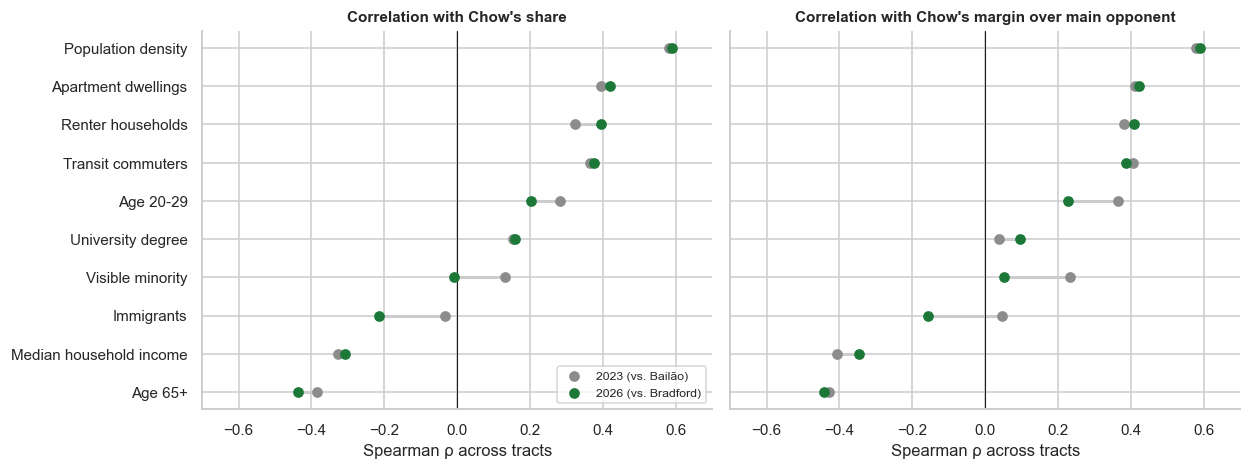

In [29]:
rows = []
for p in PRIMARY:
    rows.append({"var": PRIMARY[p], "share23": stats.spearmanr(*t[[p, "chow23"]].dropna().T.values)[0], "share26": stats.spearmanr(*t[[p, "chow26"]].dropna().T.values)[0],
                 "margin23": stats.spearmanr(*t[[p, "margin23"]].dropna().T.values)[0], "margin26": stats.spearmanr(*t[[p, "margin26"]].dropna().T.values)[0]})
G = pd.DataFrame(rows).set_index("var")
order = (G.share26).sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for a, (c23, c26, ttl) in zip(ax, (("share23", "share26", "Correlation with Chow's share"), ("margin23", "margin26", "Correlation with Chow's margin over main opponent"))):
    g = G.loc[order]; a.hlines(g.index, g[c23], g[c26], color="#cccccc", lw=2); a.scatter(g[c23], g.index, color=C23, s=36, zorder=3, label="2023 (vs. Bailão)"); a.scatter(g[c26], g.index, color=C26, s=36, zorder=3, label="2026 (vs. Bradford)")
    a.axvline(0, color="k", lw=.7); a.set(title=ttl, xlabel="Spearman ρ across tracts", xlim=(-.7, .7))
ax[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

**Persistent gradients and ones that moved.** Density (0.58 → 0.59), age 65+ (−0.39 → −0.44), transit, apartments and income (−0.33 → −0.31) correlate with Chow's share about as strongly in 2026 as in 2023, and renters slightly more (0.32 → 0.40): **persistent differences**. The gradients that **changed** are visible minority (0.13 → −0.01 for share; 0.23 → 0.05 for margin), immigrants (−0.03 → −0.21; 0.05 → −0.16, crossing zero) and age 20-29 (0.28 → 0.20; 0.36 → 0.23): in 2023 Chow did relatively better against Bailão in tracts with more visible-minority residents; by 2026 that advantage was gone.

### 6.4 What a few of the relationships look like

Points are tracts (transparent); the large markers are medians of Chow's outcome within ten equal-sized groups of tracts, and the line is a straight-line fit, except for density, where the relationship bends and a LOWESS curve (a flexible local average) is shown instead. Correlation ρ is Spearman.

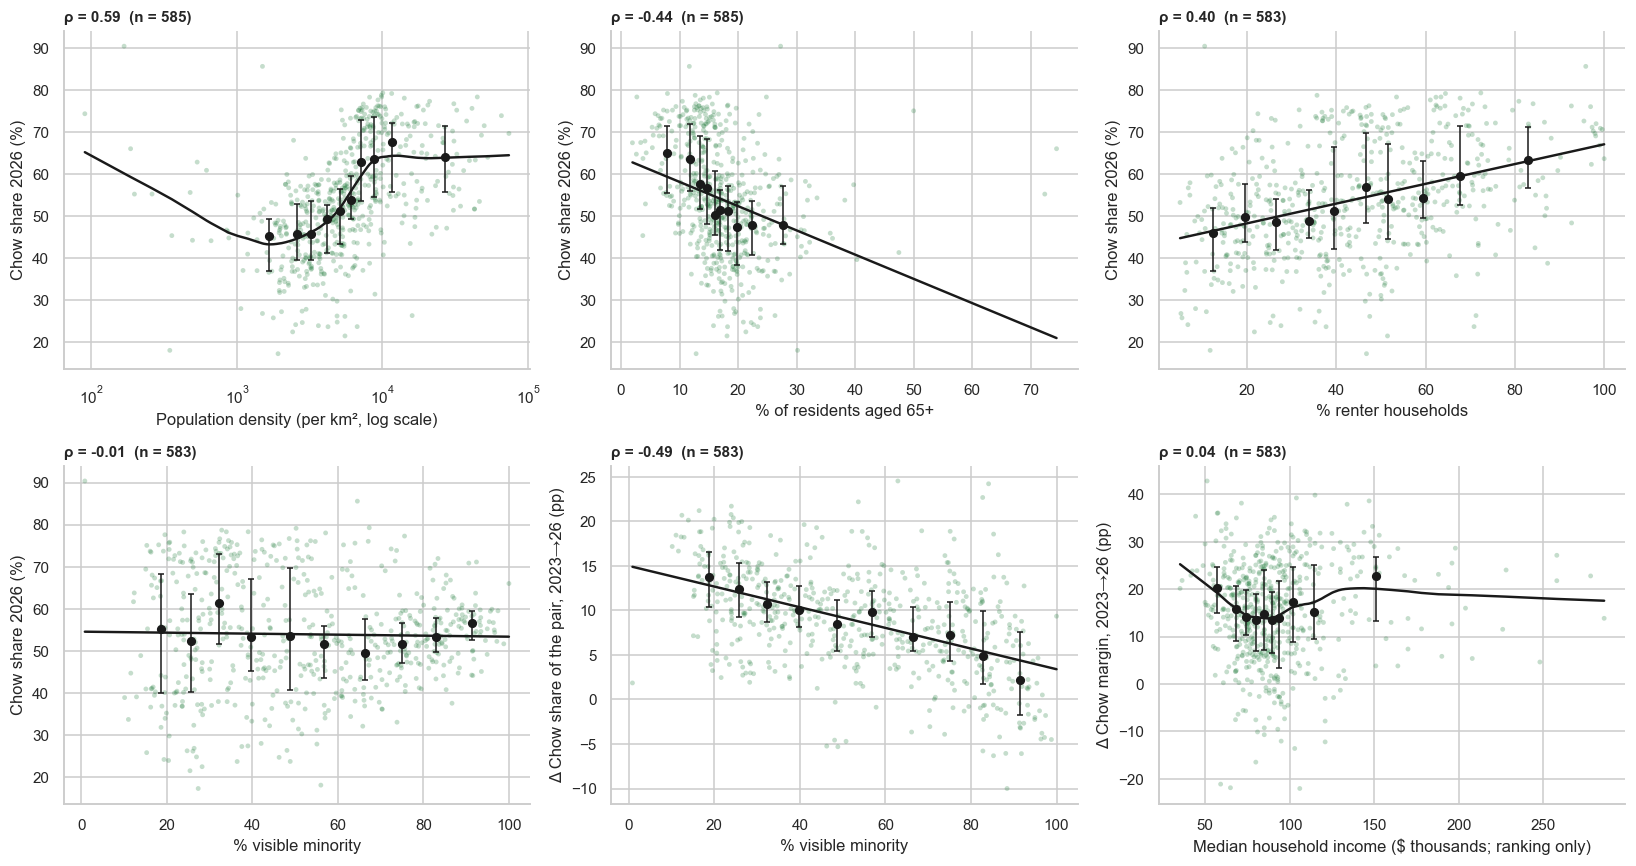

In [30]:
def scatter_binned(ax, x, y, xl, yl, xscale=1.0, logx=False, smoother="line", color=CHOW):
    d = pd.concat([x, y], axis=1).dropna(); d.columns = ["x", "y"]; d["x"] = d["x"] * xscale
    ax.scatter(d.x, d.y, s=10, alpha=.25, color=color, edgecolor="none")
    d["bin"] = pd.qcut(d.x, 10, duplicates="drop"); g = d.groupby("bin", observed=True).agg(x=("x", "median"), y=("y", "median"), lo=("y", lambda s: s.quantile(.25)), hi=("y", lambda s: s.quantile(.75)))
    ax.errorbar(g.x, g.y, yerr=[g.y - g.lo, g.hi - g.y], fmt="o", color="k", ms=5, lw=1, capsize=2, zorder=3)
    xs = np.log(d.x) if logx else d.x
    if smoother == "lowess":
        ln = lowess(d.y, xs, frac=.5); ax.plot(np.exp(ln[:, 0]) if logx else ln[:, 0], ln[:, 1], color="k", lw=1.6)
    else:
        b = np.polyfit(xs, d.y, 1); grid = np.linspace(xs.min(), xs.max(), 50); ax.plot(np.exp(grid) if logx else grid, np.polyval(b, grid), color="k", lw=1.6)
    if logx: ax.set_xscale("log")
    ax.set(xlabel=xl, ylabel=yl); ax.set_title(f"ρ = {stats.spearmanr(d.x, d.y)[0]:.2f}  (n = {len(d)})", loc="left")

panels = [("popdsqkm__nc", "chow26", "Population density (per km², log scale)", "Chow share 2026 (%)", 1, True, "lowess"),
          ("agec065p_pct", "chow26", "% of residents aged 65+", "Chow share 2026 (%)", 100, False, "line"),
          ("hhtnrent_pct", "chow26", "% renter households", "Chow share 2026 (%)", 100, False, "line"),
          ("vminvisi_pct", "chow26", "% visible minority", "Chow share 2026 (%)", 100, False, "line"),
          ("vminvisi_pct", "d_pair", "% visible minority", "Δ Chow share of the pair, 2023→26 (pp)", 100, False, "line"),
          ("ihat_med__nc", "d_margin", "Median household income ($ thousands; ranking only)", "Δ Chow margin, 2023→26 (pp)", 1e-3, False, "lowess")]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, (p, o, xl, yl, sc, lg, sm_) in zip(axes.ravel(), panels):
    scatter_binned(a, t[p], t[o], xl, yl, xscale=sc, logx=lg, smoother=sm_)
plt.tight_layout(); plt.show()

**Shapes.** Density acts like a threshold: Chow's share is roughly flat at about 45% up to ~3,000 people/km² and then climbs to 60-65% by 10,000. Age 65+ is a steady decline. Renter share is a looser rise. Visible-minority share has no relationship to her 2026 level, but tracts with more visible-minority residents had smaller gains against her opponent (Δ share of the pair falls from about +14 points at low minority share to about +3 at the highest). Income shows no overall slope for change in margin; low-income and high-income tracts both gained, middle-income tracts a bit less.

## 7. Tracts of a given composition, in both elections

The **same census-based groups** are used in 2023 and 2026. These describe voting *in areas with a particular composition*; they do not describe how renters or racialized residents voted. Shares are pooled (votes summed, then divided); counts of tracts and votes are in the labels.

### 7.1 Renter-concentrated and visible-minority-majority tracts (≥70%)

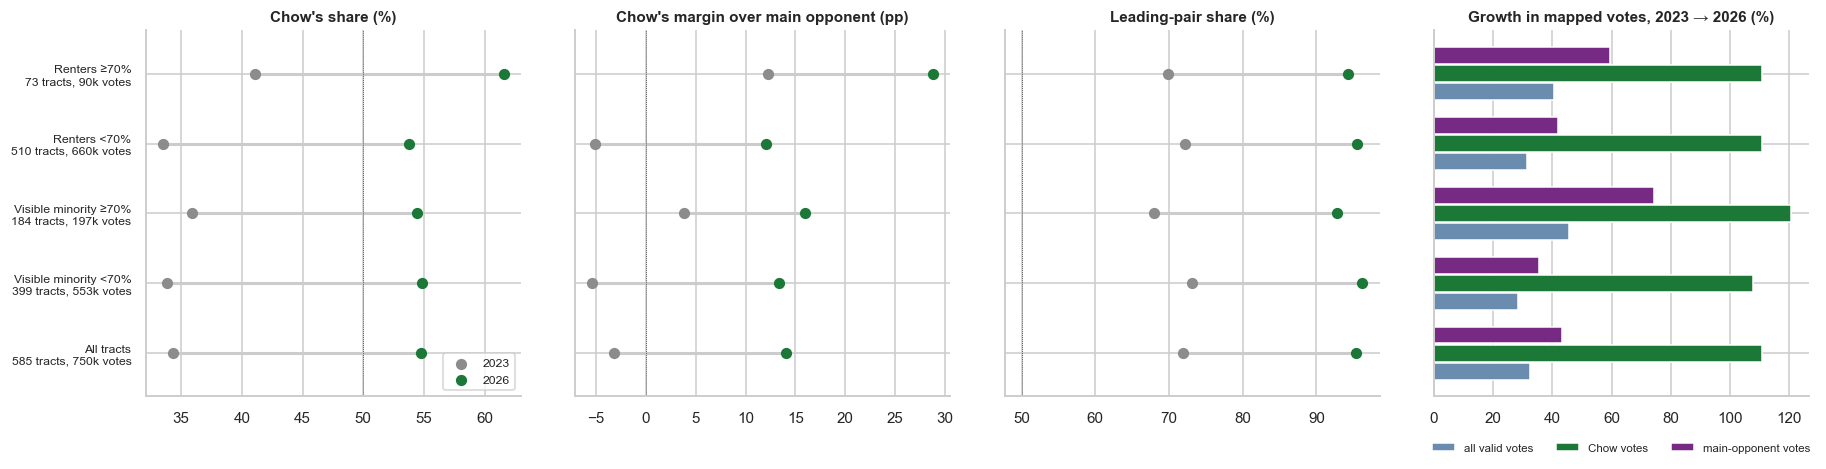

,chow23,chow26,margin23,margin26,lp23,lp26,g_valid,g_chow,g_opp
label,,,,,,,,,
"Renters ≥70% – 73 tracts, 90k votes",41.10,61.60,12.20,28.80,69.90,94.30,40.50,110.70,59.50
"Renters <70% – 510 tracts, 660k votes",33.50,53.80,-5.20,12.10,72.20,95.50,31.40,110.80,41.80
"Visible minority ≥70% – 184 tracts, 197k votes",35.90,54.40,3.80,16.00,68.00,92.80,45.50,120.50,74.20
"Visible minority <70% – 399 tracts, 553k votes",33.90,54.80,-5.40,13.40,73.20,96.30,28.30,107.60,35.40
"All tracts – 585 tracts, 750k votes",34.40,54.70,-3.20,14.10,71.90,95.40,32.40,110.80,43.30


Difference in the 2023→2026 change between the two groups (pooled; pp unless stated)


,Δ Chow share,Δ margin,Δ share of pair,Δ leading-pair share,vote growth (% pts)
Renters ≥70% minus <70%,0.23,-0.61,-3.34,1.08,9.17
Visible minority ≥70% minus <70%,-2.41,-6.58,-4.82,1.76,17.14


In [31]:
def mk(mask, label):
    g = t[mask]; r = pooled(g); r["label"] = f"{label}\n{len(g)} tracts, {g.valid26.sum() / 1e3:.0f}k votes"; r["eq_d_margin"] = g.d_margin.mean(); r["eq_d_chow"] = g.d_chow.mean(); r["eq_d_pair"] = g.d_pair.mean(); r["eq_d_lp"] = g.d_lp.mean(); return r
T = HEADLINE_THRESHOLD; hasr, hasv = t.hhtnrent_pct.notna(), t.vminvisi_pct.notna()
grp = pd.DataFrame([mk(hasr & (t.hhtnrent_pct >= T), "Renters ≥70%"), mk(hasr & (t.hhtnrent_pct < T), "Renters <70%"), mk(hasv & (t.vminvisi_pct >= T), "Visible minority ≥70%"),
                    mk(hasv & (t.vminvisi_pct < T), "Visible minority <70%"), mk(t.chow26.notna(), "All tracts")])
ypos = np.arange(len(grp))[::-1]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
for a, (c23, c26, ttl) in zip(ax[:3], (("chow23", "chow26", "Chow's share (%)"), ("margin23", "margin26", "Chow's margin over main opponent (pp)"), ("lp23", "lp26", "Leading-pair share (%)"))):
    a.hlines(ypos, grp[c23], grp[c26], color="#cccccc", lw=2); a.scatter(grp[c23], ypos, color=C23, s=40, zorder=3, label="2023"); a.scatter(grp[c26], ypos, color=C26, s=40, zorder=3, label="2026")
    a.set(title=ttl); a.axvline(0 if "margin" in c23 else 50, color="k", lw=.5, ls=":")
for off, (c, colr, nm) in zip((-.26, 0, .26), (("g_valid", "#6a8caf", "all valid votes"), ("g_chow", CHOW, "Chow votes"), ("g_opp", OPP, "main-opponent votes"))):
    ax[3].barh(ypos + off, grp[c], height=.24, color=colr, label=nm)
ax[3].set(title="Growth in mapped votes, 2023 → 2026 (%)"); ax[3].legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3, frameon=False)
ax[0].set_yticks(ypos); ax[0].set_yticklabels(grp.label, fontsize=8); ax[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
display(grp.set_index(grp.label.str.replace("\n", " – "))[["chow23", "chow26", "margin23", "margin26", "lp23", "lp26", "g_valid", "g_chow", "g_opp"]].round(1))
gaps = pd.DataFrame({"Renters ≥70% minus <70%": grp.iloc[0][["d_chow", "d_margin", "d_pair", "d_lp", "g_valid"]] - grp.iloc[1][["d_chow", "d_margin", "d_pair", "d_lp", "g_valid"]],
                     "Visible minority ≥70% minus <70%": grp.iloc[2][["d_chow", "d_margin", "d_pair", "d_lp", "g_valid"]] - grp.iloc[3][["d_chow", "d_margin", "d_pair", "d_lp", "g_valid"]]}).T
gaps.columns = ["Δ Chow share", "Δ margin", "Δ share of pair", "Δ leading-pair share", "vote growth (% pts)"]
print("Difference in the 2023→2026 change between the two groups (pooled; pp unless stated)"); display(gaps.round(1))

**Renter-concentrated (≥70%) and visible-minority-majority (≥70%) tracts.** In **renter-heavy tracts** Chow's share was 61.6% in 2026 (vs. 53.8% elsewhere) and her margin +28.8 (vs. +12.1); the same premium existed in 2023 (margin +12.2 vs. −5.2), so the *gain* was about the same inside and outside (margin −0.6 pooled, +2.1 per tract equal-weighted: no meaningful difference). In **visible-minority-majority tracts** her 2026 share (54.4%) was the same as elsewhere (54.8%), but her gains were smaller: share gain 2.4 points less, margin gain 6.6 points less, share-of-pair gain 4.8 points less. They also consolidated less (92.8% vs. 96.3% in 2026). **Votes grew faster in these tracts** (mapped valid votes +45.5% vs. +28.3%), and the opponent's votes grew much faster (+74.2% vs. +35.4%) than Chow's (+120.5% vs. +107.6%). These are statements about tracts of a given composition, not about how renters or racialized residents voted.

### 7.2 Does the cut-off matter?

The same difference (high-concentration tracts minus the rest), pooled, at 60%, 70% and 80%. Each panel is one outcome; the three dots are the three thresholds.

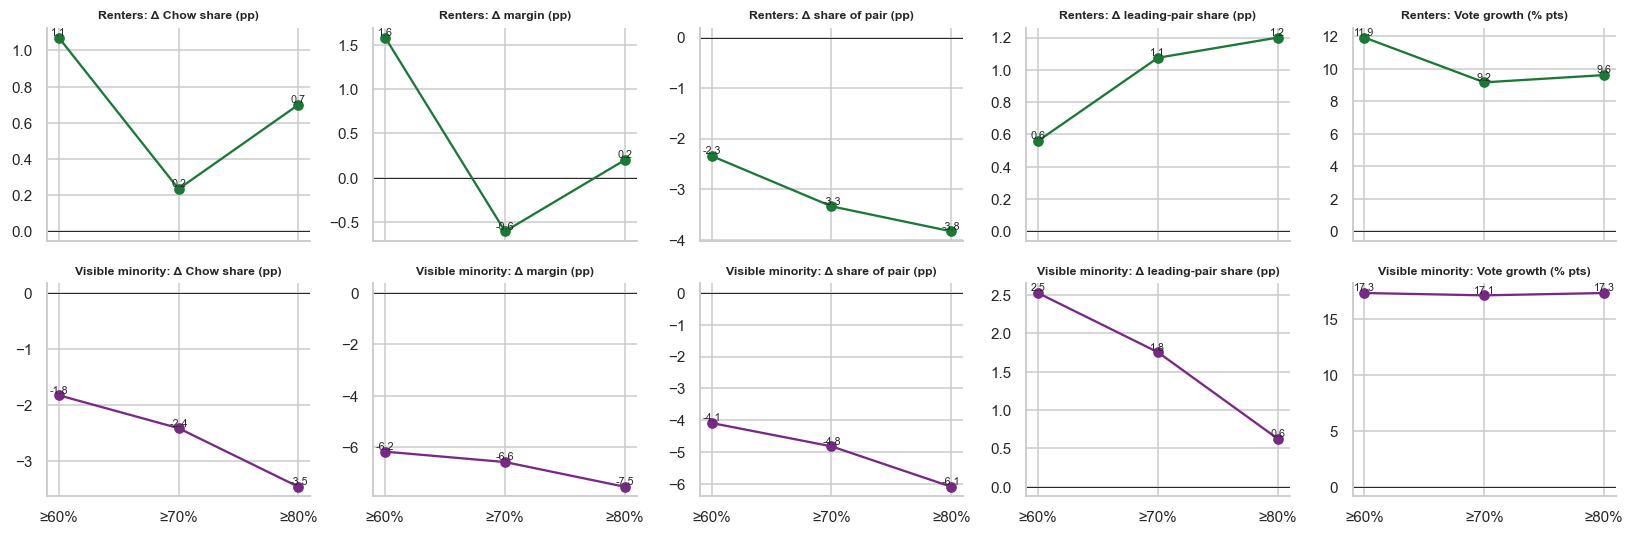

Tracts at each threshold - renters: [141, 73, 35] | visible minority: [242, 184, 109]


In [32]:
metrics = [("d_chow", "Δ Chow share (pp)"), ("d_margin", "Δ margin (pp)"), ("d_pair", "Δ share of pair (pp)"), ("d_lp", "Δ leading-pair share (pp)"), ("g_valid", "Vote growth (% pts)")]
fig, ax = plt.subplots(2, 5, figsize=(15, 5), sharex=True)
for i, (var, nm) in enumerate((("hhtnrent_pct", "Renters"), ("vminvisi_pct", "Visible minority"))):
    for j, (m_, ml) in enumerate(metrics):
        diffs = []
        for th in THRESHOLDS:
            hi = pooled(t[t[var] >= th]); lo = pooled(t[t[var] < th]); diffs.append(hi[m_] - lo[m_])
        a = ax[i, j]; a.axhline(0, color="k", lw=.6); a.plot([int(x * 100) for x in THRESHOLDS], diffs, "o-", color=CHOW if i == 0 else OPP)
        a.set_title(f"{nm}: {ml}", fontsize=8); a.set_xticks([60, 70, 80]); a.set_xticklabels(["≥60%", "≥70%", "≥80%"])
        for x_, d_ in zip((60, 70, 80), diffs): a.text(x_, d_, f"{d_:.1f}", fontsize=7, ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("Tracts at each threshold - renters:", [int((t.hhtnrent_pct >= th).sum()) for th in THRESHOLDS], "| visible minority:", [int((t.vminvisi_pct >= th).sum()) for th in THRESHOLDS])

**Cut-off check.** For visible minority the direction and rough size are stable at 60%, 70% and 80%: share gain 1.8 to 3.5 points lower, margin gain 6.2 to 7.5 lower, pair-share gain 4.1 to 6.1 lower, and vote growth about 17 points higher at every cut-off. For renters the differences in the gains are small and change sign with the cut-off (margin +1.6, −0.6, +0.2), so no conclusion should rest on renters' change; their level premium (previous figure) is the robust part.

### 7.3 Quintiles: is it a threshold or a gradient?

Fifths of tracts for five census variables, with the actual range of each fifth on the axis. First the *levels* (Chow's share and margin in 2023 and 2026), then the *gains* and the growth in voting volume.

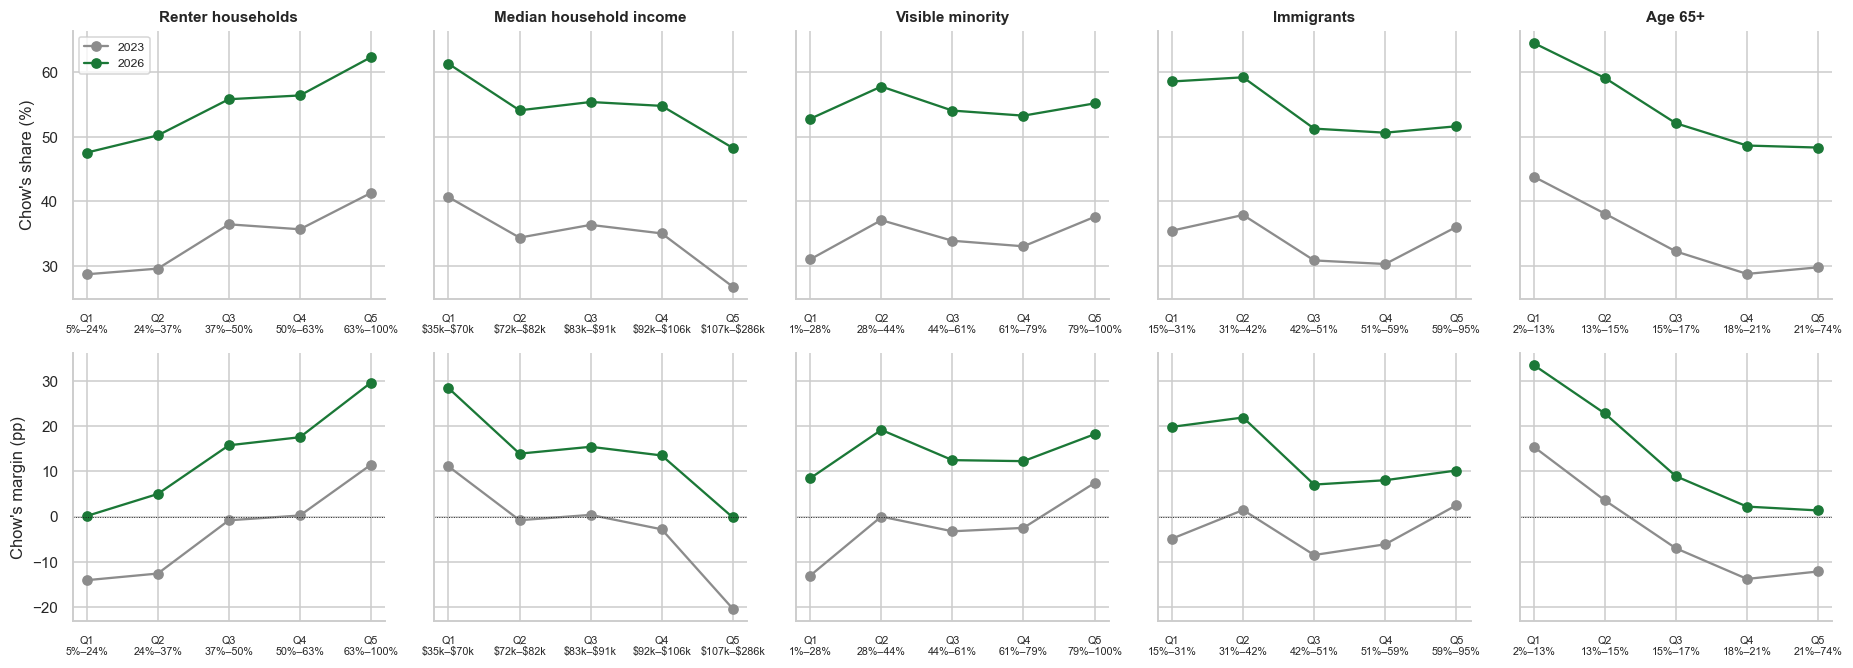

In [33]:
fig, ax = plt.subplots(2, 5, figsize=(17, 6.2), sharey="row")
for j, (v, nm) in enumerate(QV.items()):
    d = QP[v]
    for i, (c23, c26, yl) in enumerate((("chow23", "chow26", "Chow's share (%)"), ("margin23", "margin26", "Chow's margin (pp)"))):
        a = ax[i, j]; a.plot(d.q, d[c23], "o-", color=C23, label="2023"); a.plot(d.q, d[c26], "o-", color=C26, label="2026")
        a.set_xticks(d.q); a.set_xticklabels(d.tick, fontsize=7); a.set_title(nm if i == 0 else ""); 
        if j == 0: a.set_ylabel(yl)
        if i == 1: a.axhline(0, color="k", lw=.6, ls=":")
ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Levels across fifths of tracts.** Renter share and age 65+ give steady, near-parallel gradients in both elections (renters: 2026 share from 47.6% to 62.3% across the fifths; age 65+: 64.6% to 48.4%); the income fifths are close to a straight decline with the top fifth the weakest (Chow's margin ~0 in 2026 vs. +28 in the lowest-income fifth). Visible minority and immigrants are non-monotonic: the fifth with the lowest share is weakest, then support rises, and the highest fifths sit around the city average, and the 2023-to-2026 gap between the lines is smaller at the high end.

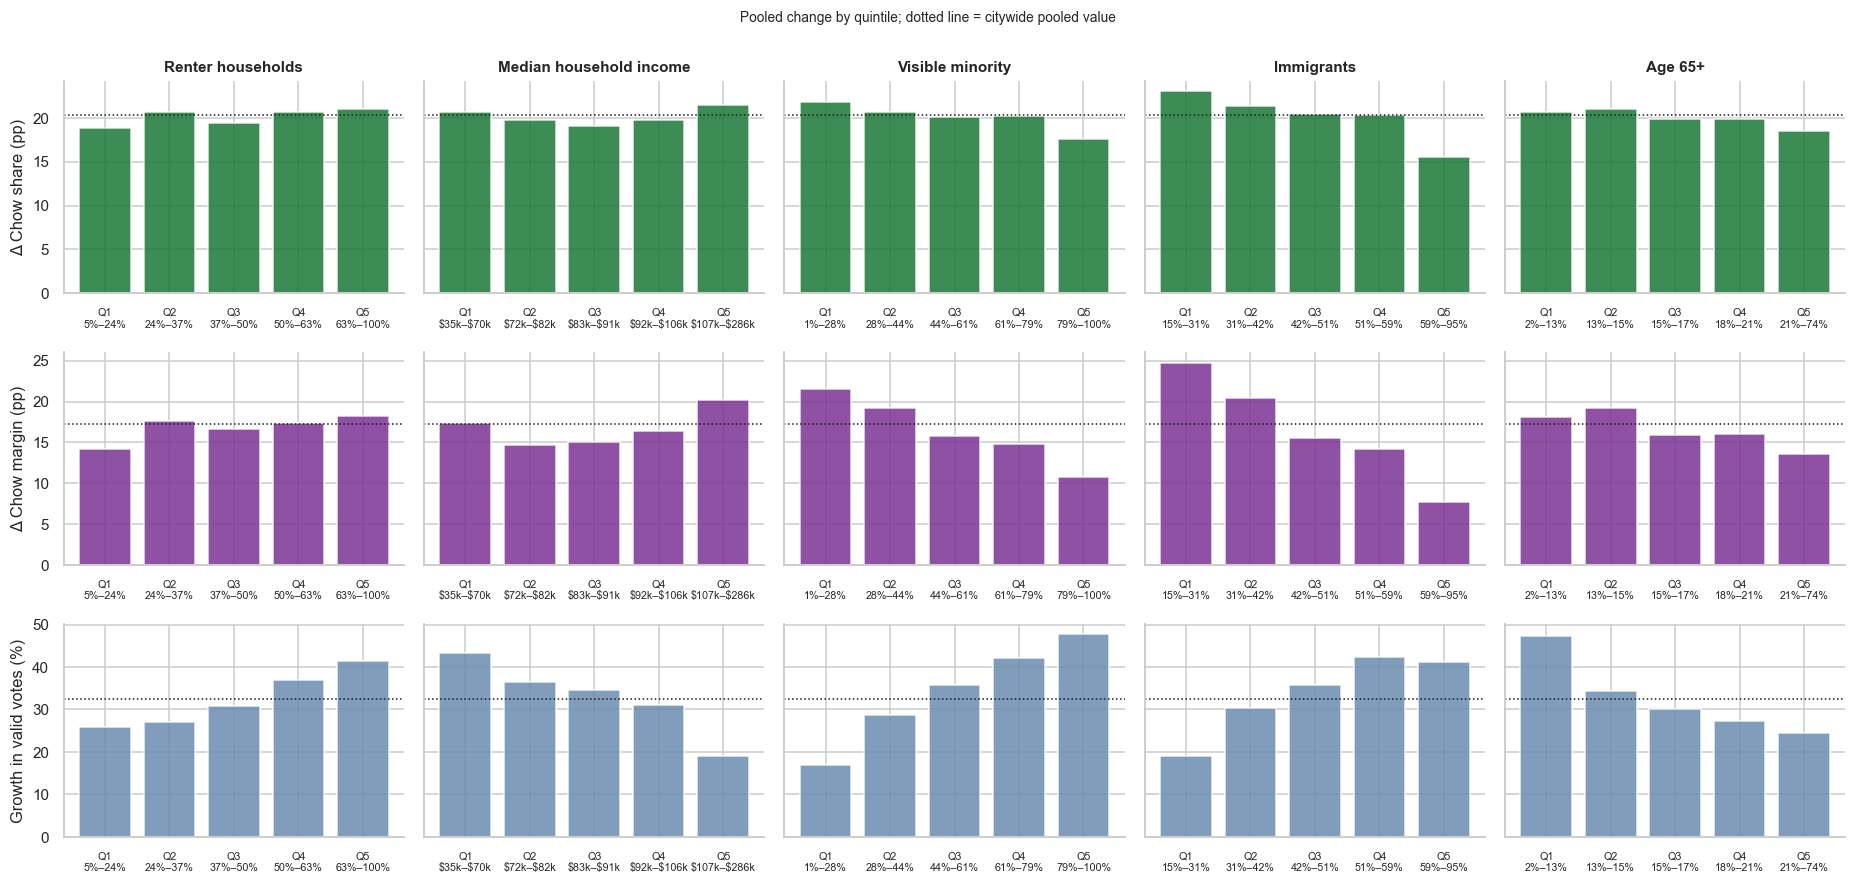

Tracts per quintile (renters / income / minority / immigrants / 65+): {'Renter households': [117, 116, 117, 117, 116], 'Median household income': [119, 123, 116, 110, 115], 'Visible minority': [117, 116, 117, 116, 117], 'Immigrants': [117, 116, 117, 116, 117], 'Age 65+': [117, 118, 116, 117, 117]}


In [34]:
fig, ax = plt.subplots(3, 5, figsize=(17, 8), sharey="row")
for j, (v, nm) in enumerate(QV.items()):
    d = QP[v]
    for i, (c, yl, colr) in enumerate((("d_chow", "Δ Chow share (pp)", CHOW), ("d_margin", "Δ Chow margin (pp)", "#7b3294"), ("g_valid", "Growth in valid votes (%)", "#6a8caf"))):
        a = ax[i, j]; a.bar(d.q, d[c], color=colr, alpha=.85); a.set_xticks(d.q); a.set_xticklabels(d.tick, fontsize=7); a.axhline(P[c], color="k", ls=":", lw=1)
        if i == 0: a.set_title(nm)
        if j == 0: a.set_ylabel(yl)
plt.suptitle("Pooled change by quintile; dotted line = citywide pooled value", fontsize=9, y=1.0); plt.tight_layout(); plt.show()
print("Tracts per quintile (renters / income / minority / immigrants / 65+):", {nm: QP[v]["n"].astype(int).tolist() for v, nm in QV.items()})

**Gains across fifths.** Share gains are nearly flat across renter and income fifths (about 19-21 points), and fall with visible-minority share (21.7 → 17.5) and especially immigrant share (23.1 → 15.6). Margin gains fall more sharply: from +24.7 points in the lowest-immigrant fifth to +7.7 in the highest, and from +21.5 to +10.7 for visible minority; for income, the lowest and highest fifths gained most. The bottom row is **voting volume**: mapped valid votes grew 17% in the lowest visible-minority fifth and 47% in the highest, 19% vs. 41% for immigrants, 26% vs. 41% for renters, and 43% vs. 19% for income (lowest vs. highest), and 47% vs. 24% for age 65+ (lowest vs. highest).

### 7.3b Mapped votes per 100 census residents (volume context, **not turnout**)

Valid mapped votes divided by the tract's 2021 census population, pooled by quintile. This includes children and non-citizens in the denominator and covers mapped votes only, so it is a rough *volume intensity*, not an eligible-elector turnout rate; it helps show whether faster vote growth came from tracts that started with fewer votes per resident.

Citywide mapped valid votes per 100 census residents: 2023 20.3 -> 2026 26.8


/tmp/ipykernel_1285106/3722043103.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g = d.groupby("q").apply(lambda x: pd.Series({"v23": x.valid23.sum() / x.pop21.sum() * 100, "v26": x.valid26.sum() / x.pop21.sum() * 100}))
/tmp/ipykernel_1285106/3722043103.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g = d.groupby("q").apply(lambda x: pd.Series({"v23": x.valid23.sum() / x.pop21.sum() * 100, "v26":

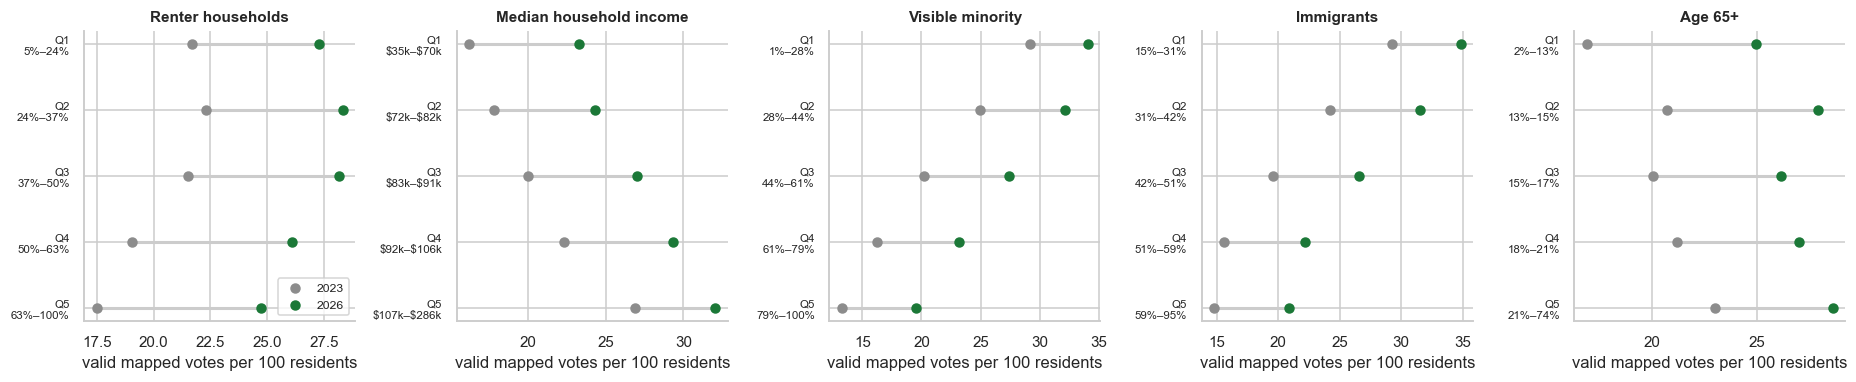

In [35]:
t["pop21"] = t["den_agec_tot"]
print(f"Citywide mapped valid votes per 100 census residents: 2023 {t.valid23.sum() / t.pop21.sum() * 100:.1f} -> 2026 {t.valid26.sum() / t.pop21.sum() * 100:.1f}")
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, (v, nm) in zip(ax, QV.items()):
    d = t.dropna(subset=[v]).copy(); d["q"] = pd.qcut(d[v], 5, labels=False) + 1
    g = d.groupby("q").apply(lambda x: pd.Series({"v23": x.valid23.sum() / x.pop21.sum() * 100, "v26": x.valid26.sum() / x.pop21.sum() * 100}))
    a.hlines(g.index, g.v23, g.v26, color="#cccccc", lw=2); a.scatter(g.v23, g.index, color=C23, s=34, zorder=3, label="2023"); a.scatter(g.v26, g.index, color=C26, s=34, zorder=3, label="2026")
    a.set_yticks(QP[v].q); a.set_yticklabels(QP[v].tick, fontsize=7.5); a.invert_yaxis(); a.set_title(nm); a.set_xlabel("valid mapped votes per 100 residents")
ax[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

**Volume context.** Citywide, mapped valid votes rose from 20.3 to 26.8 per 100 census residents. The tracts where votes grew fastest started from fewer votes per resident: in the highest visible-minority fifth the figure rose from about 13 to 20 per 100, in the lowest from about 29 to 34; in the lowest-income fifth from about 16 to 23, in the highest from about 27 to 32. Faster percentage growth therefore partly means catching up from a low base, but gaps remained in 2026. This is not turnout (the denominator includes children and non-citizens and the numerator only mapped votes).

### 7.4 Renters × visible minority

Four fixed groups (≥70% vs. <70% on each). Each cell shows the pooled value and the number of tracts; cells with fewer than 40 tracts are starred as sparse. The two tracts with missing census data are excluded, not counted as "<70%".

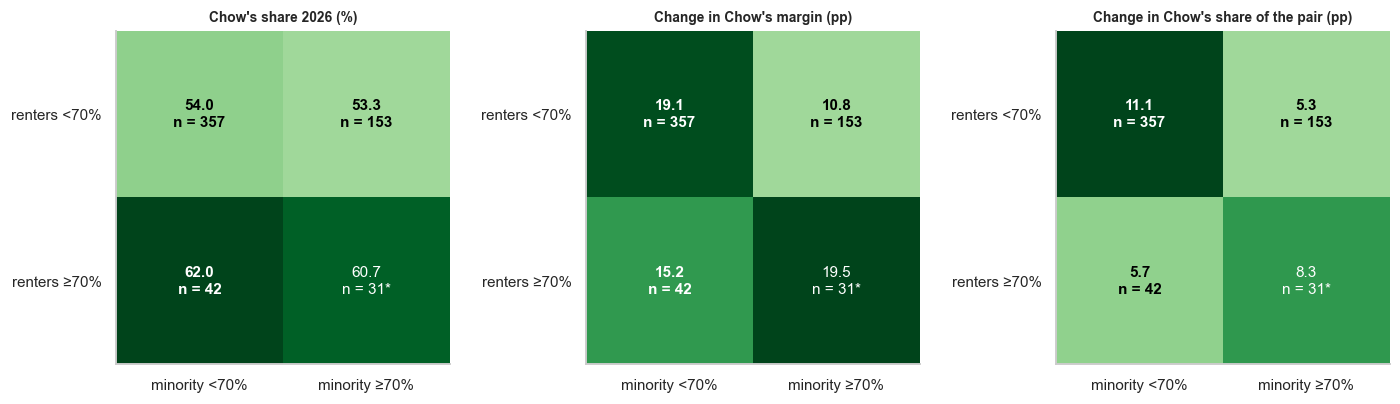

* fewer than 40 tracts (sparse)


In [36]:
cells = {}
for r_hi in (False, True):
    for v_hi in (False, True):
        m_ = (t.hhtnrent_pct >= T) == r_hi; m_ &= (t.vminvisi_pct >= T) == v_hi; m_ &= hasr & hasv
        cells[(r_hi, v_hi)] = (pooled(t[m_]), int(m_.sum()))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (key, ttl, cmap, ctr) in zip(ax, (("chow26", "Chow's share 2026 (%)", "Greens", None), ("d_margin", "Change in Chow's margin (pp)", "Greens", None), ("d_pair", "Change in Chow's share of the pair (pp)", "Greens", None))):
    vals = np.array([[cells[(r, v)][0][key] for v in (False, True)] for r in (False, True)]); ns = np.array([[cells[(r, v)][1] for v in (False, True)] for r in (False, True)])
    a.imshow(vals, cmap=cmap, vmin=vals.min() - (vals.max() - vals.min()) * .6, vmax=vals.max())
    for i in range(2):
        for j in range(2):
            dark = (vals[i, j] - vals.min()) / (vals.max() - vals.min() + 1e-9) > .45
            a.text(j, i, f"{vals[i, j]:.1f}\nn = {ns[i, j]}{'*' if ns[i, j] < SPARSE_N else ''}", ha="center", va="center", fontsize=10, color="white" if dark else "black", fontweight="bold" if ns[i, j] >= SPARSE_N else "normal")
    a.set_xticks([0, 1]); a.set_xticklabels(["minority <70%", "minority ≥70%"]); a.set_yticks([0, 1]); a.set_yticklabels(["renters <70%", "renters ≥70%"]); a.set_title(ttl, fontsize=9); a.grid(False)
plt.tight_layout(); plt.show(); print("* fewer than", SPARSE_N, "tracts (sparse)")

**Renters × visible minority.** In 2026 Chow's share is higher in renter-heavy tracts regardless of minority share (62.0% and 60.7%* vs. 54.0% and 53.3%). The weaker gains are concentrated in tracts that are minority-majority but not renter-majority (n = 153): margin gain +10.8 and pair-share gain +5.3, against +19.1 and +11.1 in tracts that are neither. In renter-heavy tracts the gains are in between, and differ little by minority share (pair-share gain +5.7 vs. +8.3), though the minority-majority renter cell is sparse (31 tracts) and should not be interpreted.

## 8. Targeted checks

Four questions about the central findings: do very small tracts drive them, do pooled and equal-tract summaries disagree, do cut-offs matter (answered in §7.2), and is a citywide association misleading because the pattern inside wards differs.

### 8.1 Small tracts and pooled vs. equal-tract

In [37]:
def key_metrics(df):
    pc = lambda a, b: stats.spearmanr(*df[[a, b]].dropna().T.values)[0]
    rg = pooled(df[df.hhtnrent_pct >= T]); rl = pooled(df[df.hhtnrent_pct < T]); vg = pooled(df[df.vminvisi_pct >= T]); vl = pooled(df[df.vminvisi_pct < T])
    return {"tracts": len(df), "pooled Δ Chow share (pp)": pooled(df).d_chow, "tract median Δ Chow share (pp)": df.d_chow.median(), "tract SD of Δ Chow share": df.d_chow.std(),
            "tracts where Chow's share rose (%)": (df.d_chow > 0).mean() * 100, "ρ Chow 2026 share ~ age 65+": pc("chow26", "agec065p_pct"), "ρ Chow 2026 share ~ density": pc("chow26", "popdsqkm__nc"),
            "ρ Chow 2026 share ~ renters": pc("chow26", "hhtnrent_pct"), "ρ Δ share of pair ~ visible minority": pc("d_pair", "vminvisi_pct"),
            "renters ≥70% minus <70%: Δ margin (pp)": rg.d_margin - rl.d_margin, "minority ≥70% minus <70%: Δ pair share (pp)": vg.d_pair - vl.d_pair}
ks = pd.DataFrame({"all tracts": key_metrics(t), f"excluding small tracts (< {MIN_VALID_VOTES} votes)": key_metrics(t[t.big])})
display(ks.round(2))
eq = pd.DataFrame({"pooled": [grp.iloc[0].d_margin - grp.iloc[1].d_margin, grp.iloc[2].d_margin - grp.iloc[3].d_margin, grp.iloc[0].d_pair - grp.iloc[1].d_pair, grp.iloc[2].d_pair - grp.iloc[3].d_pair],
                   "equal-tract mean": [grp.iloc[0].eq_d_margin - grp.iloc[1].eq_d_margin, grp.iloc[2].eq_d_margin - grp.iloc[3].eq_d_margin, grp.iloc[0].eq_d_pair - grp.iloc[1].eq_d_pair, grp.iloc[2].eq_d_pair - grp.iloc[3].eq_d_pair]},
                  index=["renters ≥70% minus <70%: Δ margin", "minority ≥70% minus <70%: Δ margin", "renters ≥70% minus <70%: Δ share of pair", "minority ≥70% minus <70%: Δ share of pair"])
print("High-concentration minus other tracts: pooled vs. equal-tract means (pp)"); display(eq.round(1))

,all tracts,excluding small tracts (< 300 votes)
tracts,585.00,557.00
pooled Δ Chow share (pp),20.35,20.38
tract median Δ Chow share (pp),20.00,20.14
tract SD of Δ Chow share,5.13,5.06
tracts where Chow's share rose (%),100.00,100.00
ρ Chow 2026 share ~ age 65+,-0.44,-0.45
ρ Chow 2026 share ~ density,0.59,0.61
ρ Chow 2026 share ~ renters,0.40,0.40
ρ Δ share of pair ~ visible minority,-0.49,-0.48
renters ≥70% minus <70%: Δ margin (pp),-0.61,-0.79


High-concentration minus other tracts: pooled vs. equal-tract means (pp)


,pooled,equal-tract mean
renters ≥70% minus <70%: Δ margin,-0.60,2.10
minority ≥70% minus <70%: Δ margin,-6.60,-5.90
renters ≥70% minus <70%: Δ share of pair,-3.30,-1.60
minority ≥70% minus <70%: Δ share of pair,-4.80,-5.00


**Do small tracts or tract weighting drive this?** No. Dropping the 28 tracts under 300 valid votes (1.1% of mapped votes) changes none of the headline numbers (pooled share gain 20.35 vs. 20.38; median 20.0 vs. 20.1; the correlations to within ±0.02). Pooled and equal-tract summaries agree for the visible-minority comparisons (margin gain −6.6 vs. −5.9; pair share gain −4.8 vs. −5.0). They disagree in sign for renters' margin gain (−0.6 pooled vs. +2.1 equal-tract), another sign that there is no clear renter difference in gains.

### 8.2 Citywide vs. within-ward patterns (visible minority share)

A citywide association can mix two things: differences *between* parts of the city and differences *within* them. The left panels show the citywide scatter. The right panels subtract each tract-group's ward average from both variables, so they show how tracts compare with others in the same ward (tracts grouped by dominant ward, an approximation). Below, the within-ward correlation is computed separately for each ward, with dot size showing the number of tracts.

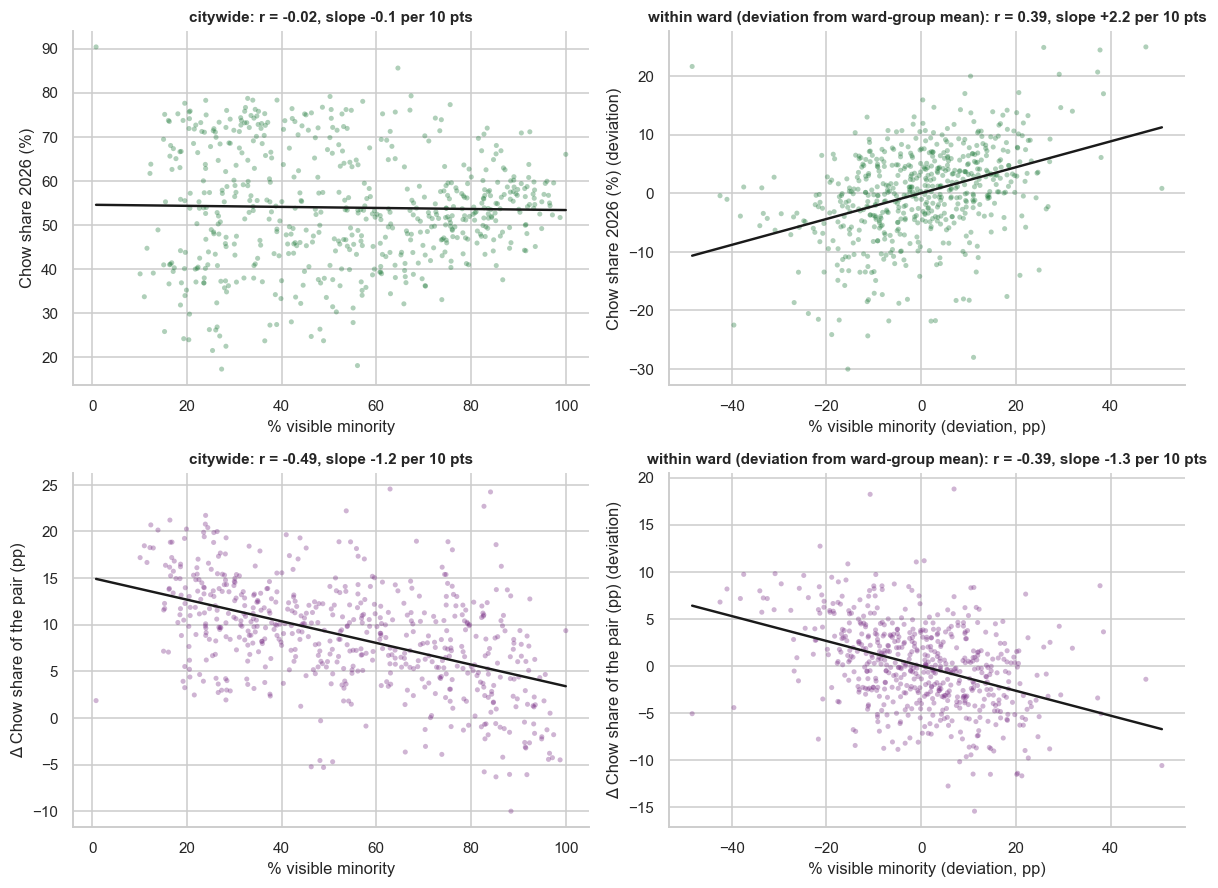

Mean tract visible-minority share (%) in the five highest wards: {'Scarborough North (23)': 92, 'Scarborough-Agincourt (22)': 83, 'Etobicoke North (1)': 77, 'Humber River-Black Creek (7)': 77, 'Scarborough-Rouge Park (25)': 75} | lowest five: {'Davenport (9)': 33, "Toronto-St. Paul's (12)": 32, 'Etobicoke-Lakeshore (3)': 32, 'Etobicoke Centre (2)': 31, 'Parkdale-High Park (4)': 28}
Between wards (25 wards): correlation of mean tract visible-minority share with Chow's ward share 2026 = -0.25; with the ward change in margin = -0.52
... in the wards with the smallest margin gains: {'York Centre': 54, 'Willowdale': 71, 'Scarborough North': 92, 'Etobicoke North': 77, 'Eglinton-Lawrence': 37}


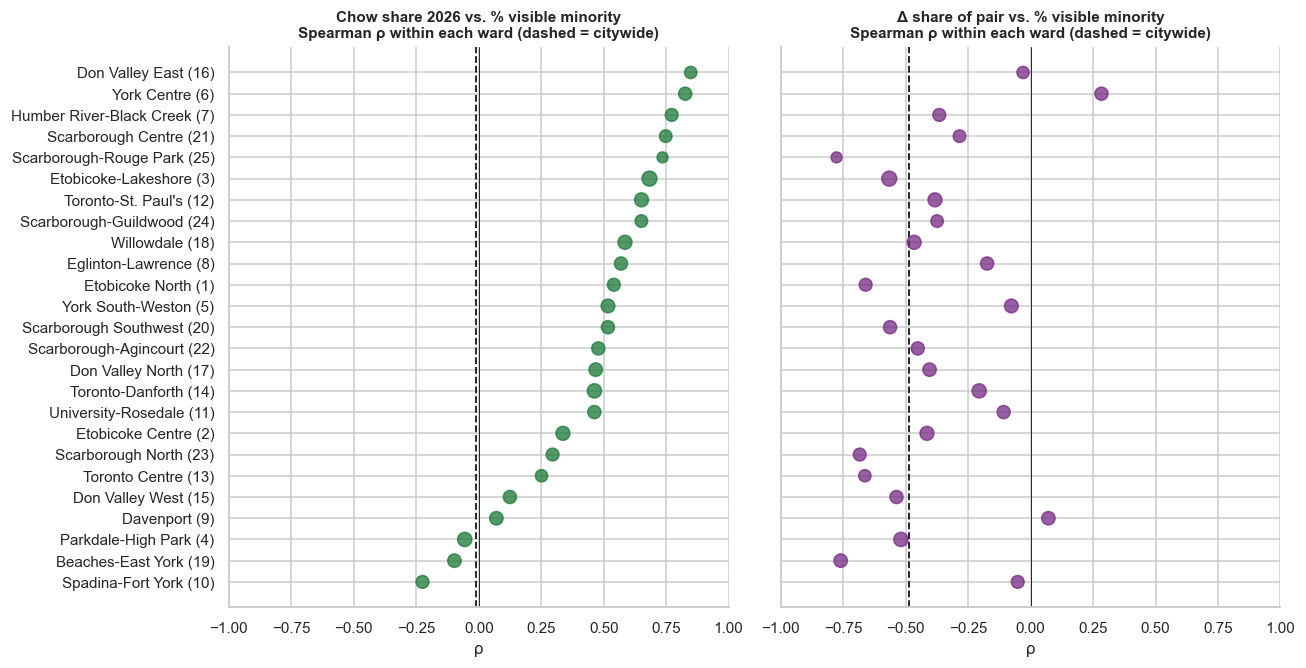

Wards with a positive within-ward ρ(Chow 2026 share, % visible minority): 22 of 25 | negative ρ(Δ share of pair, % visible minority): 23 of 25 | ward tract counts range 16 - 30


In [38]:
d = t.dropna(subset=["vminvisi_pct"]).copy(); d["vm"] = d.vminvisi_pct * 100
for c in ("vm", "chow26", "d_pair"):
    d[c + "_w"] = d[c] - d.groupby("ward_dominant")[c].transform("mean")
fig, ax = plt.subplots(2, 2, figsize=(11, 8.2))
for i, (y, yl) in enumerate((("chow26", "Chow share 2026 (%)"), ("d_pair", "Δ Chow share of the pair (pp)"))):
    for j, (xc, yc, ttl) in enumerate((("vm", y, "citywide"), ("vm_w", y + "_w", "within ward (deviation from ward-group mean)"))):
        a = ax[i, j]; a.scatter(d[xc], d[yc], s=11, alpha=.35, color=CHOW if i == 0 else OPP, edgecolor="none"); b = np.polyfit(d[xc], d[yc], 1); g = np.linspace(d[xc].min(), d[xc].max(), 20); a.plot(g, np.polyval(b, g), "k", lw=1.6)
        a.set(xlabel="% visible minority" + (" (deviation, pp)" if j else ""), ylabel=yl + (" (deviation)" if j else ""), title=f"{ttl}: r = {np.corrcoef(d[xc], d[yc])[0, 1]:.2f}, slope {b[0] * 10:+.1f} per 10 pts")
plt.tight_layout(); plt.show()

per = []
for w_, g in d.groupby("ward_dominant"):
    per.append({"ward": w_, "n": len(g), "chow26": stats.spearmanr(g.vm, g.chow26)[0], "d_pair": stats.spearmanr(g.vm, g.d_pair)[0]})
per = pd.DataFrame(per).set_index("ward")
vm_by_ward = d.groupby("ward_dominant")["vm"].mean().sort_values(ascending=False)
print("Mean tract visible-minority share (%) in the five highest wards:", {f"{ward_names[w]} ({w})": round(v) for w, v in vm_by_ward.head(5).items()}, "| lowest five:", {f"{ward_names[w]} ({w})": round(v) for w, v in vm_by_ward.tail(5).items()})
bw = pd.DataFrame({"vm": vm_by_ward, "chow26": W.chow26, "d_margin": W.d_margin}).dropna()
print(f"Between wards (25 wards): correlation of mean tract visible-minority share with Chow's ward share 2026 = {bw.vm.corr(bw.chow26):.2f}; with the ward change in margin = {bw.vm.corr(bw.d_margin):.2f}")
print("... in the wards with the smallest margin gains:", {ward_names[w]: round(vm_by_ward[w]) for w in (6, 18, 23, 1, 8)})
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2), sharey=True)
for a, (c, ttl, citywide) in zip(ax, (("chow26", "Chow share 2026 vs. % visible minority", stats.spearmanr(d.vm, d.chow26)[0]), ("d_pair", "Δ share of pair vs. % visible minority", stats.spearmanr(d.vm, d.d_pair)[0]))):
    p_ = per.sort_values("chow26") if c == "chow26" else per.loc[per.sort_values("chow26").index]
    labs = [f"{ward_names[w]} ({w})" for w in p_.index]; a.scatter(p_[c], labs, s=p_.n * 3.2, color=CHOW if c == "chow26" else OPP, alpha=.75, zorder=3)
    a.axvline(0, color="k", lw=.6); a.axvline(citywide, color="k", ls="--", lw=1.2); a.set(title=ttl + "\nSpearman ρ within each ward (dashed = citywide)", xlabel="ρ", xlim=(-1, 1))
plt.tight_layout(); plt.show()
print("Wards with a positive within-ward ρ(Chow 2026 share, % visible minority):", int((per.chow26 > 0).sum()), "of 25 | negative ρ(Δ share of pair, % visible minority):", int((per.d_pair < 0).sum()), "of 25",
      "| ward tract counts range", per.n.min(), "-", per.n.max())

**Citywide vs. within-ward.** Across the city, visible-minority share is unrelated to Chow's 2026 share (r = −0.02), but **within wards the relationship is positive** (r = +0.39, about +2.2 points of Chow share per 10 points of visible-minority share), and positive in 22 of 25 wards. The citywide near-zero is the net of a positive within-ward relationship and an opposite between-ward one: across the 25 wards, those with a higher mean visible-minority share had slightly lower Chow shares (r = −0.25, a loose relationship with 25 points). For her gain in the share of the pair the picture is consistent: negative citywide (r = −0.49), negative within wards (−0.39, about −1.3 points per 10 points of visible-minority share) and negative in 23 of 25 wards (the exceptions are York Centre and Davenport). So the weaker gains in higher visible-minority tracts are a *within-ward* pattern as well as a between-ward one, whereas the citywide absence of a relationship with her level is a composition effect. Wards have 16-30 tracts, so each ward's dot is imprecise.

## 9. Technical notes and limits

- **Allocation.** Votes were reported for polling subdivisions and spread over 2021 census tracts by population-weighted areal interpolation (each polygon intersected with tracts, and with dissemination areas weighted by adult-citizen counts). The mayoral tract columns come from an upstream `.dta` built outside this repository; re-deriving 2026 with the in-repo method reproduced the city totals but differed by 20-30 votes per tract on average. Tract values are estimates with unquantified allocation error, especially for small tracts, and 2023 and 2026 use different polling-subdivision polygons, so tract-level *changes in counts* include allocation differences as well as real change.
- **Coverage.** Tract data cover mapped poll votes only (§1). Whether advance, mail-in and unmapped votes resemble the mapped votes within each tract is unknown.
- **Timing and meaning of census data.** 2021 census characteristics describe residents, not voters; non-citizens and under-18s are in the census but not the electorate.
- **Spatial clustering.** Neighbouring tracts are alike, so the 585 tracts are far fewer than 585 independent observations. Correlations here are descriptive; I report no p-values or intervals, and none of the associations should be read as independent demographic "effects".
- **Change vs. baseline.** A tract's change is built from its own 2023 value, so baseline-versus-change relationships are partly mechanical and are not interpreted as evidence of convergence or regression to the mean.
- **Ward groupings.** "Dominant-ward" groupings approximate wards by the ward holding most of each tract (45 tracts straddle ward lines); exact ward totals come from the source files.

## 10. Takeaways

Evidence is labelled **clear descriptive pattern** (large, visible in several views, robust to the checks above), or **tentative** (suggestive but depends on a convention, a small number of tracts, or the mapped-vote coverage). All findings describe **mapped votes** unless stated; official all-method figures are given where they differ.

### 1. The 2026 result was a consolidated two-candidate contest, and the official gain against the main opponent was modest (clear descriptive pattern)
- **Finding.** Chow's rise from 37.2% to 54.2% of the official vote coincides with the leading pair's combined share rising from 69.6% to 95.3%. Against her main opponent the official change was smaller than the mapped votes suggest.
- **Numbers.** Official margin +4.7 → +13.0 (change +8.3; +17.3 on mapped votes); share of the pair 53.4% → 56.8% (+3.5; +9.6 mapped); field-contraction term 14.1 of her 17.0-point gain in official share (about 12.3 of 20.3 on mapped votes).
- **Where.** Citywide; the mapped-vs-official gap is largest in the wards where her 2023 advance and mail-in vote was strong (York Centre, Eglinton-Lawrence, Willowdale, Scarborough North official margin fell).
- **Figures.** The opening paired stacked bars (§1.2), then the consolidation decomposition by ward (§5.1).
- **Qualification.** The decomposition is arithmetic with an order convention (both orderings given); it says nothing about individual voters. Mapped votes omit 22-24% of ballots.

### 2. Chow gained almost everywhere, but not equally: the smallest gains are in the north and north-west, and that is where the opponent's lead persists (clear descriptive pattern)
- **Finding.** Share rose in every tract (median +20.0 points), yet margin gains varied widely (SD 10.4) and the head-to-head lead stayed with the opponent in the north-west and north.
- **Numbers.** 148 tracts moved to Chow head-to-head, 2 to the opponent, 179 stayed with the opponent. Lowest ward margin changes: York Centre (−3.0), Willowdale (+3.4), Scarborough North (+5.6) vs. Beaches-East York (+26.8), Davenport (+25.3). 41 tracts had share up but margin narrowed (13 in York Centre).
- **Where.** York Centre, Willowdale, Scarborough North, Etobicoke North and Eglinton-Lawrence; largest in the central east end and downtown.
- **Figures.** The margin-change map and head-to-head map (§3.1B), plus the ward dumbbell panel (§3.6).
- **Qualification.** Mapped votes; the official margin change is negative in four wards. Tract-level changes include allocation differences between election years.

### 3. Raw votes, shares and voting volume tell different stories (clear descriptive pattern, with allocation caveats)
- **Finding.** Chow's additional votes came largely from the downtown and east-end wards, while growth in mapped voting volume was fastest elsewhere; vote counts follow tract size and should not be read as shifts in support.
- **Numbers.** Chow +215,705 mapped votes (+111%) vs. total valid votes +32%; five wards supplied 29% of her added votes (Spadina-Fort York 7.0%, Toronto Centre 5.9%). Volume grew +56% in Spadina-Fort York, +54% in Etobicoke North, but +18% in Eglinton-Lawrence (+40% officially). Roughly half to 70% of her added votes are the share term under the benchmark.
- **Where.** Largest additional votes: Spadina-Fort York, Toronto Centre, Beaches-East York.
- **Figures.** The additional-votes and volume-growth maps (§3.1C) with the ward contribution chart (§4.3).
- **Qualification.** Voting volume is not turnout; 2023 was a by-election, 2026 a regular election; the mapped coverage differs by ward, as Eglinton-Lawrence shows.

### 4. Visible-minority-majority and immigrant-heavy tracts: weaker gains for Chow, faster growth in votes, less consolidation (clear descriptive pattern; interpretation tentative)
- **Finding.** In tracts that are at least 70% visible minority, Chow's share was the same as elsewhere in 2026 but her gains were smaller and the opponent's vote grew far faster.
- **Numbers.** 184 tracts (197k mapped votes): margin gain 6.6 points less, pair-share gain 4.8 less; opponent votes +74% vs. +35%; leading-pair share 92.8% vs. 96.3%. The relationship holds within 23 of 25 wards. Spearman ρ with leading-pair share in 2026: −0.74 (visible minority), −0.73 (immigrants).
- **Where.** The weakest ward-level margin gains are in York Centre, Willowdale, Scarborough North and Etobicoke North, but these are not all high-minority wards (mean tract visible-minority share: Scarborough North 92%, Etobicoke North 77%, Willowdale 71%, York Centre 54%, and Eglinton-Lawrence 37%), so the pattern is not simply a list of high-minority wards. Within the city's tracts it is concentrated in minority-majority tracts that are not renter-majority.
- **Figures.** The group dumbbells (§7.1) and the within-ward scatter (§8.2).
- **Qualification.** Ecological association between places; census describes residents and not voters; the interplay of income, age, tenure and geography is not separated here. A difference between two different opponents' vote is not a transfer.

### 5. Persistent neighbourhood divides alongside shifts (clear descriptive pattern)
- **Finding.** Density, age and housing sorted Chow's support in both elections; renter-heavy tracts gave her about 8 points more than other tracts in both years (so no differential gain), while the visible-minority and immigrant gradients faded or reversed.
- **Numbers.** Density ρ 0.58 → 0.59; age 65+ −0.39 → −0.44; renters ≥70%: 61.6% vs. 53.8% in 2026 and margin gap 17.4 → 16.7 points. Visible minority ρ with share 0.13 → −0.01; immigrants −0.03 → −0.21.
- **Where.** Contrast the downtown/east-end renter belt with older, lower-density tracts across the north and west.
- **Figures.** The correlation dumbbell (§6.3) and the quintile level plots (§7.3).
- **Qualification.** Correlations are descriptive, heavily clustered in space, and several predictors overlap; the visible-minority pattern is clearer inside wards than citywide.

### Tested but not developed
- **Renters and the *change* in support:** no consistent difference (sign changes with cut-off and weighting).
- **Fine-grained income patterns:** no simple slope; the income gradient in levels is clear but change is U-shaped.
- **Outright tract winners vs. head-to-head:** they differ in only a couple of tracts, so no separate story.
- **Turnout:** no eligible-elector denominator is available for tracts.